In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load processed sales dataset

file_path = "../data/processed/store_1_grocery_sales.csv"

df = pd.read_csv(file_path)

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
     id       date  store_nbr     family   sales  onpromotion
0    12 2013-01-01          1  GROCERY I     0.0            0
1  1794 2013-01-02          1  GROCERY I  2652.0            0
2  3576 2013-01-03          1  GROCERY I  2121.0            0
3  5358 2013-01-04          1  GROCERY I  2056.0            0
4  7140 2013-01-05          1  GROCERY I  2216.0            0


In [4]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (1684, 6)

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Data Types:
id                      int64
date           datetime64[us]
store_nbr               int64
family                    str
sales                 float64
onpromotion             int64
dtype: object

Missing Values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate Rows:
0

Statistical Summary:
                 id                        date  store_nbr        sales  \
count  1.684000e+03                        1684     1684.0  1684.000000   
mean   1.499565e+06  2015-04-24 08:27:04.703088        1.0  2223.172803   
min    1.200000e+01         2013-01-01 00:00:00        1.0     0.000000   
25%    7.497885e+05         2014-02-26 18:00:00        1.0  1873.500000   
50%    1.499565e+06         2015-04-24 12:00:00        1.0  2283.500000   
75%    2.249342e+06         2016-06-19 06:00:00        1.0  2649.000000  

In [5]:
# Check date range

print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

# Generate expected daily dates

expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

# Compare actual dates with expected dates

actual_dates = pd.DatetimeIndex(df["date"])

missing_dates = expected_dates.difference(actual_dates)

print("\nExpected Number of Days:", len(expected_dates))
print("Actual Number of Records:", len(df))
print("Missing Dates:", len(missing_dates))

print("\nMissing Date List:")
print(missing_dates.tolist())

Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00

Expected Number of Days: 1688
Actual Number of Records: 1684
Missing Dates: 4

Missing Date List:
[Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


In [6]:
# Display all missing dates

print("All Missing Dates:")
for date in missing_dates:
    print(date.date())

# Check sales before and after each missing date

print("\nSales Around Missing Dates:")

for date in missing_dates:

    print("\nMissing Date:", date.date())

    surrounding_data = df[
        (df["date"] >= date - pd.Timedelta(days=2)) &
        (df["date"] <= date + pd.Timedelta(days=2))
    ]

    print(surrounding_data[["date", "sales", "onpromotion"]])

All Missing Dates:
2013-12-25
2014-12-25
2015-12-25
2016-12-25

Sales Around Missing Dates:

Missing Date: 2013-12-25
          date   sales  onpromotion
356 2013-12-23  4367.0            0
357 2013-12-24  3036.0            0
358 2013-12-26  2052.0            0
359 2013-12-27  2152.0            0

Missing Date: 2014-12-25
          date   sales  onpromotion
720 2014-12-23  3231.0           14
721 2014-12-24  2958.0            6
722 2014-12-26  2450.0           11
723 2014-12-27  1310.0           14

Missing Date: 2015-12-25
           date   sales  onpromotion
1084 2015-12-23  4146.0            5
1085 2015-12-24  3126.0            6
1086 2015-12-26  1620.0           16
1087 2015-12-27   677.0            8

Missing Date: 2016-12-25
           date   sales  onpromotion
1449 2016-12-23  5386.0          125
1450 2016-12-24  3609.0          103
1451 2016-12-26   904.0           80
1452 2016-12-27  3156.0          101


In [7]:
# Create a complete daily date range

full_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

# Set date as the index and add missing dates

df = df.set_index("date")

df = df.reindex(full_dates)

# Restore date column

df.index.name = "date"
df = df.reset_index()

# Fill store and product information

df["store_nbr"] = df["store_nbr"].fillna(1)
df["family"] = df["family"].fillna("GROCERY I")

# Fill missing sales and promotion values

df["sales"] = df["sales"].fillna(0)
df["onpromotion"] = df["onpromotion"].fillna(0)

print("Missing dates handled successfully!")

print("\nNew dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nChristmas records:")
print(
    df[df["date"].dt.month.eq(12) & df["date"].dt.day.eq(25)]
    [["date", "sales", "onpromotion"]]
)

Missing dates handled successfully!

New dataset shape: (1688, 6)

Missing values:
date           0
id             4
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Christmas records:
           date  sales  onpromotion
358  2013-12-25    0.0          0.0
723  2014-12-25    0.0          0.0
1088 2015-12-25    0.0          0.0
1454 2016-12-25    0.0          0.0


In [8]:
# 1. Check the final dataset shape
print("Final dataset shape:", df.shape)

# 2. Check date range
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

# 3. Check date continuity
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

print("Expected dates:", len(expected_dates))
print("Actual dates:", df["date"].nunique())

# 4. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 5. Check duplicate dates
print("\nDuplicate dates:", df["date"].duplicated().sum())

# 6. Save the cleaned dataset
output_path = "../data/processed/store_1_grocery_sales_cleaned.csv"

df.to_csv(output_path, index=False)

print("\nCleaned dataset saved successfully!")
print("Location:", output_path)

Final dataset shape: (1688, 6)
Start date: 2013-01-01 00:00:00
End date: 2017-08-15 00:00:00
Expected dates: 1688
Actual dates: 1688

Missing values:
date           0
id             4
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate dates: 0

Cleaned dataset saved successfully!
Location: ../data/processed/store_1_grocery_sales_cleaned.csv


In [9]:
# Extract year
df["year"] = df["date"].dt.year

# Extract month
df["month"] = df["date"].dt.month

# Extract day
df["day"] = df["date"].dt.day

# Extract day of the week
# Monday = 0, Sunday = 6
df["day_of_week"] = df["date"].dt.dayofweek

# Check whether the day is a weekend
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

# Display the new features
print(df[
    ["date", "year", "month", "day",
     "day_of_week", "is_weekend"]
].head(10))

        date  year  month  day  day_of_week  is_weekend
0 2013-01-01  2013      1    1            1           0
1 2013-01-02  2013      1    2            2           0
2 2013-01-03  2013      1    3            3           0
3 2013-01-04  2013      1    4            4           0
4 2013-01-05  2013      1    5            5           1
5 2013-01-06  2013      1    6            6           1
6 2013-01-07  2013      1    7            0           0
7 2013-01-08  2013      1    8            1           0
8 2013-01-09  2013      1    9            2           0
9 2013-01-10  2013      1   10            3           0


C:\Users\Anshika Singh\AppData\Local\Temp\ipykernel_21468\3435215298.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek


In [10]:
# Calculate average sales for each day of the week

weekday_sales = df.groupby("day_of_week")["sales"].mean()

# Display average sales
print("Average Sales by Day of Week:")
print(weekday_sales)

Average Sales by Day of Week:
day_of_week
0    2383.493776
1    2408.991736
2    2758.867220
3    2219.796680
4    2403.630705
5    2322.962656
6    1026.796680
Name: sales, dtype: float64


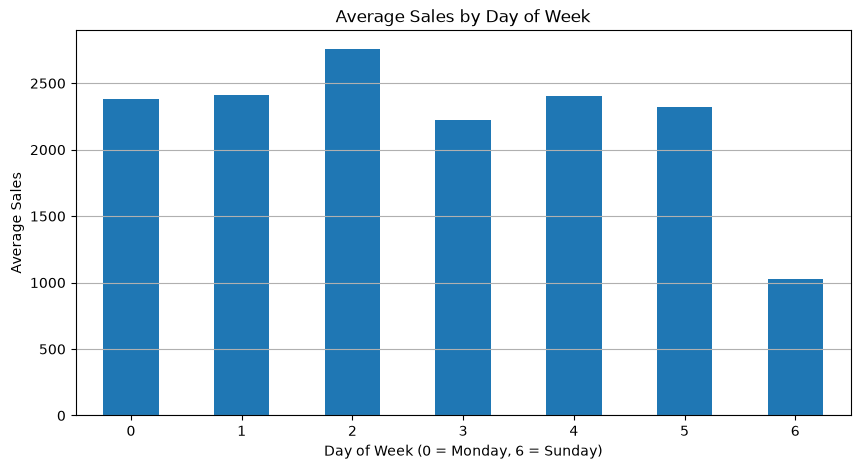

In [11]:
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week (0 = Monday, 6 = Sunday)")
plt.ylabel("Average Sales")

plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

Average Sales: Weekday vs Weekend
day_type
Weekday    2434.934494
Weekend    1674.879668
Name: sales, dtype: float64


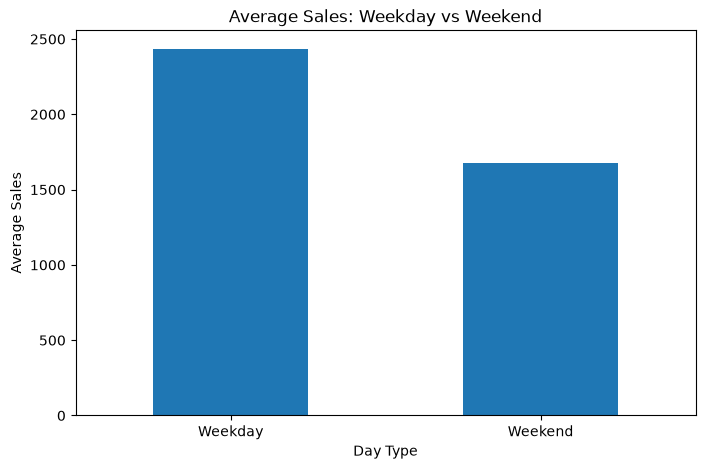

In [12]:
# Separate weekday and weekend sales

df["day_type"] = df["day_of_week"].apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate average sales
day_type_sales = df.groupby("day_type")["sales"].mean()

print("Average Sales: Weekday vs Weekend")
print(day_type_sales)

# Visualize the comparison
plt.figure(figsize=(8, 5))

day_type_sales.plot(kind="bar")

plt.title("Average Sales: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)

plt.show()

Average Sales by Month:
month
1     2109.903226
2     2091.872340
3     2214.729032
4     2343.973333
5     2183.412903
6     2268.526667
7     2178.774194
8     2033.323741
9     2126.658333
10    2224.822581
11    2201.700000
12    2682.451613
Name: sales, dtype: float64


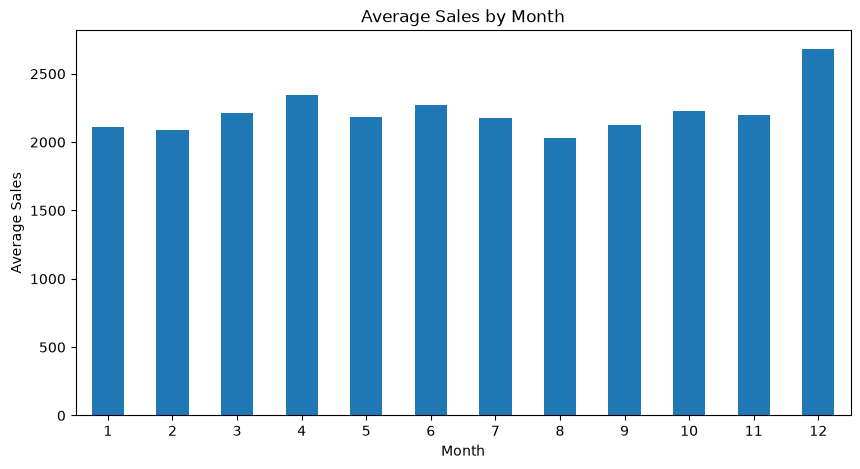

In [13]:
# Calculate average sales by month

monthly_sales = df.groupby("month")["sales"].mean()

print("Average Sales by Month:")
print(monthly_sales)

# Visualize monthly sales

plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="bar")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)

plt.show()

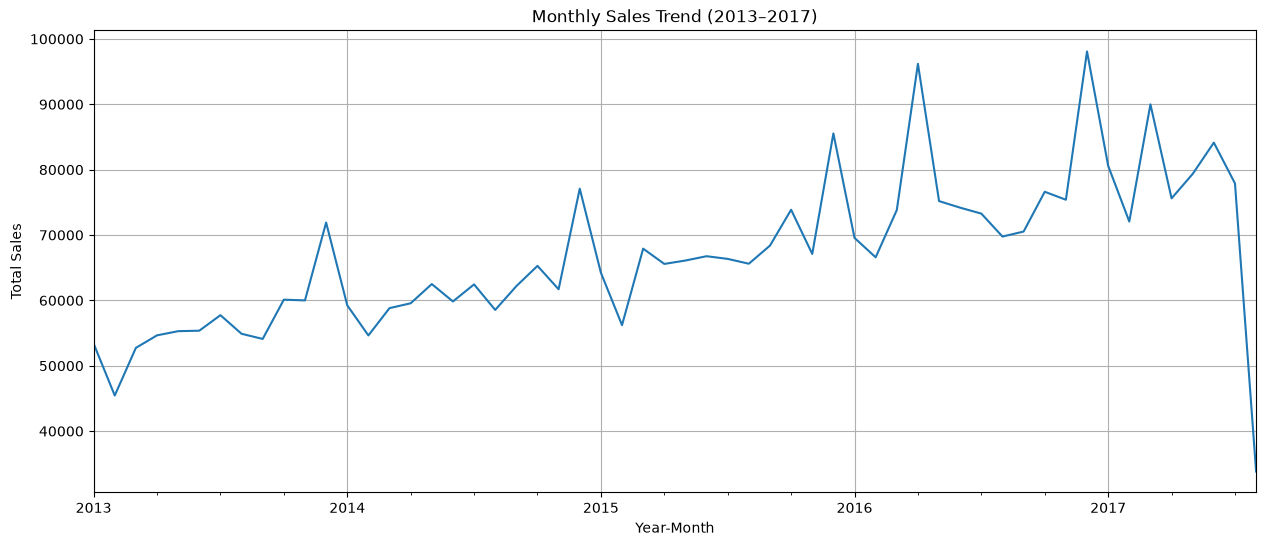

In [14]:
# Convert date into monthly periods

df["year_month"] = df["date"].dt.to_period("M")

# Calculate total sales for each month

monthly_trend = df.groupby("year_month")["sales"].sum()

# Plot monthly sales trend

plt.figure(figsize=(15, 6))

monthly_trend.plot()

plt.title("Monthly Sales Trend (2013–2017)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.grid(True)

plt.show()

In [15]:
# Calculate total sales for each year
yearly_sales = df.groupby("year")["sales"].sum()

print("Total Sales by Year:")
print(yearly_sales)

Total Sales by Year:
year
2013    675641.0
2014    741844.0
2015    813668.0
2016    919204.0
2017    593466.0
Name: sales, dtype: float64


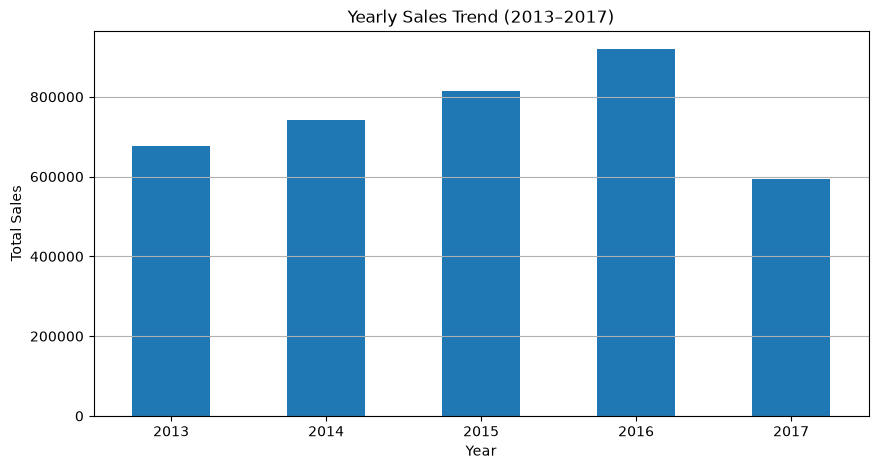

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

yearly_sales.plot(kind="bar")

plt.title("Yearly Sales Trend (2013–2017)")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.grid(axis="y")
plt.show()

In [17]:
# Display sales distribution statistics

print("Sales Distribution:")
print(df["sales"].describe())

print("\nSkewness:")
print(df["sales"].skew())

print("\nKurtosis:")
print(df["sales"].kurt())

Sales Distribution:
count    1688.000000
mean     2217.904621
std       785.835220
min         0.000000
25%      1868.750000
50%      2281.000000
75%      2646.750000
max      9065.000000
Name: sales, dtype: float64

Skewness:
0.5972330787962319

Kurtosis:
5.833728663025574


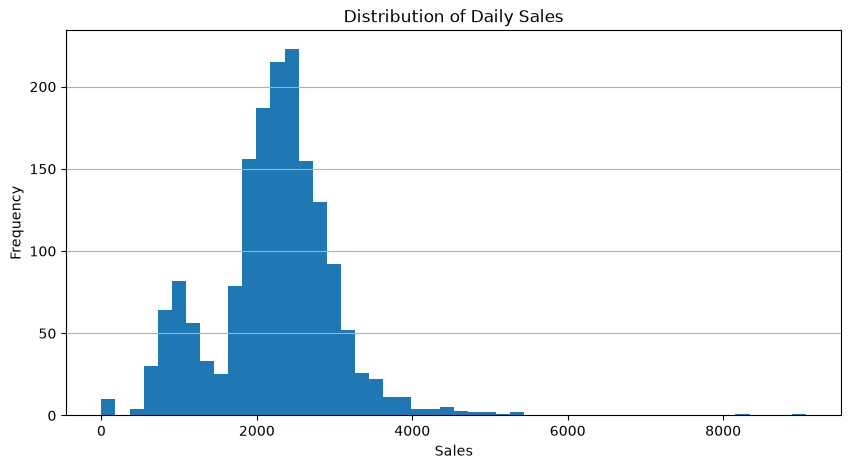

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["sales"], bins=50)

plt.title("Distribution of Daily Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.grid(axis="y")
plt.show()

In [19]:
# Calculate Q1 and Q3
Q1 = df["sales"].quantile(0.25)
Q3 = df["sales"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df[
    (df["sales"] < lower_bound) |
    (df["sales"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nLower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of potential outliers:", len(outliers))

print("\nHighest outlier records:")
print(
    outliers.nlargest(10, "sales")[
        ["date", "sales", "onpromotion"]
    ]
)

Q1: 1868.75
Q3: 2646.75
IQR: 778.0

Lower Bound: 701.75
Upper Bound: 3813.75

Number of potential outliers: 74

Highest outlier records:
           date   sales  onpromotion
1203 2016-04-18  9065.0         18.0
1204 2016-04-19  8221.0         19.0
1205 2016-04-20  5438.0         28.0
1452 2016-12-23  5386.0        125.0
1450 2016-12-21  5162.0        116.0
1451 2016-12-22  5055.0        116.0
1526 2017-03-07  4917.0         41.0
1207 2016-04-22  4871.0         26.0
1206 2016-04-21  4768.0         39.0
1408 2016-11-09  4669.0         94.0


In [20]:
# Identify all potential outliers
outliers = df[
    (df["sales"] < lower_bound) |
    (df["sales"] > upper_bound)
].copy()

# Count outliers with and without promotions
outliers["has_promotion"] = (
    outliers["onpromotion"] > 0
)

print("Total outliers:", len(outliers))

print("\nPromotion analysis:")
print(
    outliers["has_promotion"].value_counts()
)

print("\nAverage sales of outliers:")
print(outliers["sales"].mean())

print("\nAverage promotion count:")
print(outliers["onpromotion"].mean())

print("\nOutlier records:")
print(
    outliers[
        ["date", "sales", "onpromotion"]
    ].sort_values(
        "sales",
        ascending=False
    ).head(15)
)

Total outliers: 74

Promotion analysis:
has_promotion
True     42
False    32
Name: count, dtype: int64

Average sales of outliers:
2464.108108108108

Average promotion count:
25.06756756756757

Outlier records:
           date   sales  onpromotion
1203 2016-04-18  9065.0         18.0
1204 2016-04-19  8221.0         19.0
1205 2016-04-20  5438.0         28.0
1452 2016-12-23  5386.0        125.0
1450 2016-12-21  5162.0        116.0
1451 2016-12-22  5055.0        116.0
1526 2017-03-07  4917.0         41.0
1207 2016-04-22  4871.0         26.0
1206 2016-04-21  4768.0         39.0
1408 2016-11-09  4669.0         94.0
1442 2016-12-13  4624.0        108.0
1631 2017-06-20  4575.0         48.0
1431 2016-12-02  4522.0        101.0
708  2014-12-10  4481.0          7.0
1625 2017-06-14  4411.0         65.0


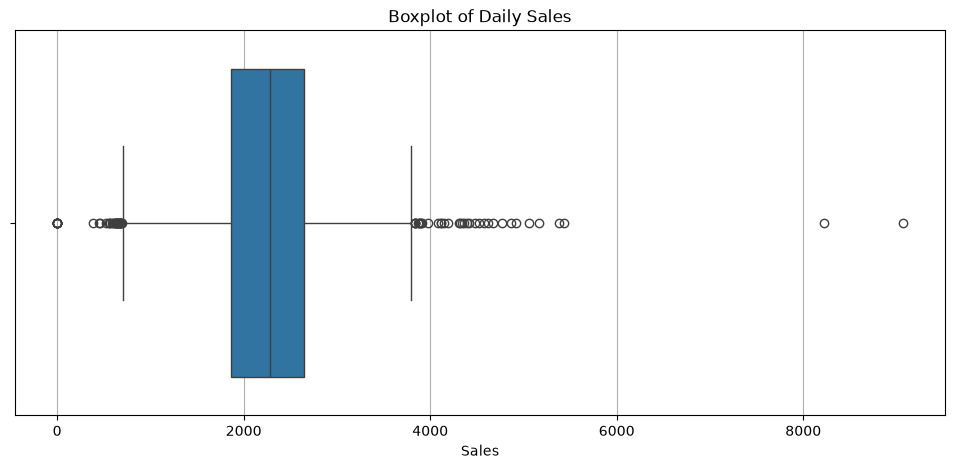

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df["sales"]
)

plt.title("Boxplot of Daily Sales")
plt.xlabel("Sales")

plt.grid(axis="x")

plt.show()

# Step 8: Feature Selection

We select the relevant features for the LSTM model.

Input Features:
- sales
- onpromotion

Target Variable:
- sales

Columns such as id, store_nbr, and family will not be used
because they are identifiers or have already been filtered.

In [22]:
# Select relevant columns

model_df = df[
    ["date", "sales", "onpromotion"]
].copy()

# Sort chronologically
model_df = model_df.sort_values("date")

# Reset index
model_df = model_df.reset_index(drop=True)

print("Selected features:")
print(model_df.head())

print("\nDataset shape:")
print(model_df.shape)

print("\nMissing values:")
print(model_df.isnull().sum())

Selected features:
        date   sales  onpromotion
0 2013-01-01     0.0          0.0
1 2013-01-02  2652.0          0.0
2 2013-01-03  2121.0          0.0
3 2013-01-04  2056.0          0.0
4 2013-01-05  2216.0          0.0

Dataset shape:
(1688, 3)

Missing values:
date           0
sales          0
onpromotion    0
dtype: int64


In [23]:

# Step 9: Chronological Train, Validation and Test Split

# Sort data by date
model_df = model_df.sort_values("date").reset_index(drop=True)

# Calculate split positions
total_records = len(model_df)

train_end = int(total_records * 0.70)
val_end = int(total_records * 0.85)

# Split the dataset chronologically
train_df = model_df.iloc[:train_end].copy()

val_df = model_df.iloc[train_end:val_end].copy()

test_df = model_df.iloc[val_end:].copy()

# Display dataset shapes
print("Training dataset:", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset:", test_df.shape)

# Display date ranges
print("\nTraining date range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation date range:")
print(val_df["date"].min(), "to", val_df["date"].max())

print("\nTesting date range:")
print(test_df["date"].min(), "to", test_df["date"].max())


Training dataset: (1181, 3)
Validation dataset: (253, 3)
Testing dataset: (254, 3)

Training date range:
2013-01-01 00:00:00 to 2016-03-26 00:00:00

Validation date range:
2016-03-27 00:00:00 to 2016-12-04 00:00:00

Testing date range:
2016-12-05 00:00:00 to 2017-08-15 00:00:00


In [24]:

# Step 10: Feature Scaling

from sklearn.preprocessing import MinMaxScaler

# Create separate scalers for sales and promotion
sales_scaler = MinMaxScaler()
promotion_scaler = MinMaxScaler()

# Fit scalers ONLY on training data
train_df.loc[:, "sales_scaled"] = sales_scaler.fit_transform(
    train_df[["sales"]]
)

train_df.loc[:, "promotion_scaled"] = promotion_scaler.fit_transform(
    train_df[["onpromotion"]]
)

# Transform validation data using training scalers
val_df.loc[:, "sales_scaled"] = sales_scaler.transform(
    val_df[["sales"]]
)

val_df.loc[:, "promotion_scaled"] = promotion_scaler.transform(
    val_df[["onpromotion"]]
)

# Transform testing data using training scalers
test_df.loc[:, "sales_scaled"] = sales_scaler.transform(
    test_df[["sales"]]
)

test_df.loc[:, "promotion_scaled"] = promotion_scaler.transform(
    test_df[["onpromotion"]]
)

# Display results
print("Original sales values:")
print(train_df["sales"].head())

print("\nScaled sales values:")
print(train_df["sales_scaled"].head())

print("\nOriginal promotion values:")
print(train_df["onpromotion"].head())

print("\nScaled promotion values:")
print(train_df["promotion_scaled"].head())

print("\nTraining scaled data:")
print(train_df[["sales_scaled", "promotion_scaled"]].describe())

print("\nValidation scaled data:")
print(val_df[["sales_scaled", "promotion_scaled"]].describe())

print("\nTesting scaled data:")
print(test_df[["sales_scaled", "promotion_scaled"]].describe())


Original sales values:
0       0.0
1    2652.0
2    2121.0
3    2056.0
4    2216.0
Name: sales, dtype: float64

Scaled sales values:
0    0.000000
1    0.591832
2    0.473332
3    0.458826
4    0.494532
Name: sales_scaled, dtype: float64

Original promotion values:
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: onpromotion, dtype: float64

Scaled promotion values:
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: promotion_scaled, dtype: float64

Training scaled data:
       sales_scaled  promotion_scaled
count   1181.000000       1181.000000
mean       0.459198          0.067457
std        0.151014          0.117444
min        0.000000          0.000000
25%        0.404151          0.000000
50%        0.476679          0.014493
75%        0.542736          0.101449
max        1.000000          1.000000

Validation scaled data:
       sales_scaled  promotion_scaled
count    253.000000        253.000000
mean       0.558978          0.617632
std        0.201455          0.326369
min

In [25]:

# Step 11A: Check scaled datasets before sequence creation

print("Training data:")
print(train_df[["date", "sales_scaled", "promotion_scaled"]].head())

print("\nValidation data:")
print(val_df[["date", "sales_scaled", "promotion_scaled"]].head())

print("\nTesting data:")
print(test_df[["date", "sales_scaled", "promotion_scaled"]].head())

print("\nDataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Training data:
        date  sales_scaled  promotion_scaled
0 2013-01-01      0.000000               0.0
1 2013-01-02      0.591832               0.0
2 2013-01-03      0.473332               0.0
3 2013-01-04      0.458826               0.0
4 2013-01-05      0.494532               0.0

Validation data:
           date  sales_scaled  promotion_scaled
1181 2016-03-27      0.218032          0.275362
1182 2016-03-28      0.515287          0.405797
1183 2016-03-29      0.602098          0.391304
1184 2016-03-30      0.587369          0.347826
1185 2016-03-31      0.537157          0.347826

Testing data:
           date  sales_scaled  promotion_scaled
1434 2016-12-05      0.636465          1.347826
1435 2016-12-06      0.262665          1.130435
1436 2016-12-07      0.824593          2.420290
1437 2016-12-08      0.691587          1.695652
1438 2016-12-09      0.964071          1.652174

Dataset sizes:
Training: 1181
Validation: 253
Testing: 254


In [27]:
import numpy as np

# Forecasting configuration
LOOKBACK = 90
HORIZON = 16

# Input features and target
FEATURE_COLUMNS = [
    "sales_scaled",
    "promotion_scaled"
]

TARGET_COLUMN = "sales_scaled"


def create_sequences(data, lookback, horizon):

    X = []
    y = []

    for i in range(lookback, len(data) - horizon + 1):

        # Previous 90 days
        input_sequence = data[
            i - lookback:i
        ][FEATURE_COLUMNS].values

        # Next 16 days of sales
        target_sequence = data[
            i:i + horizon
        ][TARGET_COLUMN].values

        X.append(input_sequence)
        y.append(target_sequence)

    return np.array(X), np.array(y)

In [28]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

Training: (1181, 5)
Validation: (253, 5)
Testing: (254, 5)

Training columns:
['date', 'sales', 'onpromotion', 'sales_scaled', 'promotion_scaled']


In [29]:
import numpy as np

LOOKBACK = 90
HORIZON = 16

FEATURE_COLUMNS = [
    "sales_scaled",
    "promotion_scaled"
]

TARGET_COLUMN = "sales_scaled"


def create_sequences(data, lookback, horizon):

    X = []
    y = []

    for i in range(lookback, len(data) - horizon + 1):

        input_sequence = data[
            i - lookback:i
        ][FEATURE_COLUMNS].values

        target_sequence = data[
            i:i + horizon
        ][TARGET_COLUMN].values

        X.append(input_sequence)
        y.append(target_sequence)

    return np.array(X), np.array(y)


def create_split_sequences(
    context_df,
    target_df,
    lookback,
    horizon
):

    combined_df = pd.concat(
        [context_df, target_df],
        ignore_index=True
    )

    context_length = len(context_df)

    X = []
    y = []

    for i in range(
        context_length,
        len(combined_df) - horizon + 1
    ):

        input_sequence = combined_df[
            i - lookback:i
        ][FEATURE_COLUMNS].values

        target_sequence = combined_df[
            i:i + horizon
        ][TARGET_COLUMN].values

        X.append(input_sequence)
        y.append(target_sequence)

    return np.array(X), np.array(y)

In [30]:
# Training sequences
X_train, y_train = create_sequences(
    train_df,
    LOOKBACK,
    HORIZON
)


# Validation: use the last 90 training days as context
X_val, y_val = create_split_sequences(
    train_df.tail(LOOKBACK),
    val_df,
    LOOKBACK,
    HORIZON
)


# Testing: use the last 90 validation days as context
X_test, y_test = create_split_sequences(
    val_df.tail(LOOKBACK),
    test_df,
    LOOKBACK,
    HORIZON
)


print("Training sequences:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation sequences:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTesting sequences:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training sequences:
X_train: (1076, 90, 2)
y_train: (1076, 16)

Validation sequences:
X_val: (238, 90, 2)
y_val: (238, 16)

Testing sequences:
X_test: (239, 90, 2)
y_test: (239, 16)


In [31]:
import torch
from torch.utils.data import Dataset, DataLoader


class SalesDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [32]:
train_dataset = SalesDataset(X_train, y_train)

val_dataset = SalesDataset(X_val, y_val)

test_dataset = SalesDataset(X_test, y_test)


print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 1076
Validation dataset: 238
Testing dataset: 239


In [33]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [34]:
X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Target batch shape:", y_batch.shape)

print("\nInput data type:", X_batch.dtype)
print("Target data type:", y_batch.dtype)

Input batch shape: torch.Size([32, 90, 2])
Target batch shape: torch.Size([32, 16])

Input data type: torch.float32
Target data type: torch.float32


In [36]:
from src.model import SalesLSTM

# Initialize model
model = SalesLSTM(input_size=2)

# Test with one batch
sample_input, sample_target = next(iter(train_loader))

# Generate predictions
predictions = model(sample_input)

print("Input shape:", sample_input.shape)
print("Target shape:", sample_target.shape)
print("Prediction shape:", predictions.shape)

ModuleNotFoundError: No module named 'src'

In [37]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\notebooks


In [38]:
import sys
from pathlib import Path

# Move one level up from notebooks to project root
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python import path
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src folder exists:", (PROJECT_ROOT / "src").exists())

Project root: c:\Users\Anshika Singh\Desktop\ai-sales-forecasting
src folder exists: True


In [39]:
from src.model import SalesLSTM

In [40]:
# Initialize LSTM model
model = SalesLSTM(input_size=2)

# Get one batch
sample_input, sample_target = next(iter(train_loader))

# Generate predictions
predictions = model(sample_input)

print("Input shape:", sample_input.shape)
print("Target shape:", sample_target.shape)
print("Prediction shape:", predictions.shape)

Input shape: torch.Size([32, 90, 2])
Target shape: torch.Size([32, 16])
Prediction shape: torch.Size([32, 16])


import torch
import torch.nn as nn
import torch.optim as optim

# Initialize the model
model = SalesLSTM(input_size=2)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Check model configuration
print("Model:")
print(model)

print("\nLoss Function:")
print(criterion)

print("\nOptimizer:")
print(optimizer)

In [41]:
import torch
import torch.nn as nn
import torch.optim as optim

# Initialize the model
model = SalesLSTM(input_size=2)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Check model configuration
print("Model:")
print(model)

print("\nLoss Function:")
print(criterion)

print("\nOptimizer:")
print(optimizer)

Model:
SalesLSTM(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=16, bias=True)
)

Loss Function:
MSELoss()

Optimizer:
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [42]:
# Check available computing device

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move model to the selected device
model = model.to(device)

print("Selected device:", device)
print("Model is ready for training.")

Selected device: cpu
Model is ready for training.


In [43]:
# Training loop

def train_one_epoch(model, train_loader, criterion, optimizer, device):

    # Set model to training mode
    model.train()

    total_loss = 0.0
    total_samples = 0

    # Iterate through batches
    for X_batch, y_batch in train_loader:

        # Move data to CPU/GPU
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        predictions = model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Accumulate loss
        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    # Calculate average loss
    average_loss = total_loss / total_samples

    return average_loss

In [44]:
def validate_one_epoch(model, val_loader, criterion, device):

    # Set model to evaluation mode
    model.eval()

    total_loss = 0.0
    total_samples = 0

    # Disable gradient calculation
    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            # Move data to device
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Generate predictions
            predictions = model(X_batch)

            # Calculate loss
            loss = criterion(predictions, y_batch)

            # Accumulate loss
            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

    # Calculate average validation loss
    average_loss = total_loss / total_samples

    return average_loss

In [45]:
from pathlib import Path

# Training configuration
EPOCHS = 50
PATIENCE = 7

best_val_loss = float("inf")
patience_counter = 0

# Store training history
history = {
    "train_loss": [],
    "val_loss": []
}

# Create model directory
Path("models").mkdir(parents=True, exist_ok=True)

# Training process
for epoch in range(EPOCHS):

    # Train for one epoch
    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validate model
    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Save losses
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.6f} "
        f"| Val Loss: {val_loss:.6f}"
    )

    # Check whether validation loss improved
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        # Save best model
        torch.save(
            model.state_dict(),
            "models/best_lstm_model.pth"
        )

        print("Best model saved!")

    else:

        patience_counter += 1

        print(
            f"No improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

    # Early stopping
    if patience_counter >= PATIENCE:

        print("Early stopping triggered!")
        break

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)

Epoch [1/50] | Train Loss: 0.094056 | Val Loss: 0.049578
Best model saved!
Epoch [2/50] | Train Loss: 0.023702 | Val Loss: 0.045661
Best model saved!
Epoch [3/50] | Train Loss: 0.022628 | Val Loss: 0.042063
Best model saved!
Epoch [4/50] | Train Loss: 0.022395 | Val Loss: 0.042213
No improvement: 1/7
Epoch [5/50] | Train Loss: 0.022212 | Val Loss: 0.046563
No improvement: 2/7
Epoch [6/50] | Train Loss: 0.022022 | Val Loss: 0.043249
No improvement: 3/7
Epoch [7/50] | Train Loss: 0.022071 | Val Loss: 0.044172
No improvement: 4/7
Epoch [8/50] | Train Loss: 0.021881 | Val Loss: 0.042544
No improvement: 5/7
Epoch [9/50] | Train Loss: 0.021938 | Val Loss: 0.042167
No improvement: 6/7
Epoch [10/50] | Train Loss: 0.021903 | Val Loss: 0.042107
No improvement: 7/7
Early stopping triggered!

Training completed!
Best validation loss: 0.042063254628236554


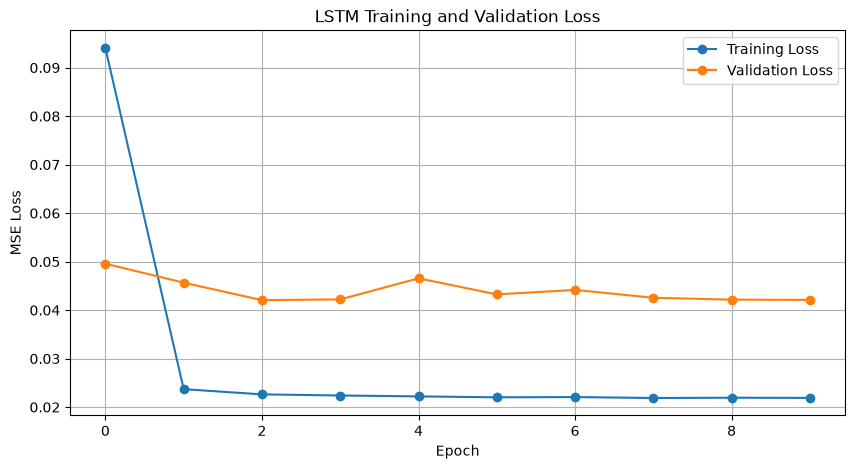

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [47]:
model.load_state_dict(
    torch.load(
        "models/best_lstm_model.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [48]:
import numpy as np

model.eval()

all_predictions = []
all_actuals = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_actuals.append(
            y_batch.numpy()
        )

# Combine all batches
all_predictions = np.concatenate(all_predictions)
all_actuals = np.concatenate(all_actuals)

print("Predictions shape:", all_predictions.shape)
print("Actual values shape:", all_actuals.shape)

Predictions shape: (239, 16)
Actual values shape: (239, 16)


In [49]:
# Convert scaled predictions into original sales values

all_predictions_original = sales_scaler.inverse_transform(
    all_predictions.reshape(-1, 1)
).reshape(all_predictions.shape)

all_actuals_original = sales_scaler.inverse_transform(
    all_actuals.reshape(-1, 1)
).reshape(all_actuals.shape)

print("Predicted sales shape:", all_predictions_original.shape)
print("Actual sales shape:", all_actuals_original.shape)

print("\nFirst 10 predicted values:")
print(all_predictions_original[0][:10])

print("\nFirst 10 actual values:")
print(all_actuals_original[0][:10])

Predicted sales shape: (239, 16)
Actual sales shape: (239, 16)

First 10 predicted values:
[2651.3472 2755.3127 2854.0269 2523.7944 2526.5615 2736.023  2567.8142
 2502.3503 2885.355  2661.4336]

First 10 actual values:
[2852.     1177.     3695.     3099.     4320.     2971.9998 1417.
 2991.     4624.     4394.    ]


In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Flatten both arrays
y_true = all_actuals_original.flatten()
y_pred = all_predictions_original.flatten()

# MAE
mae = mean_absolute_error(y_true, y_pred)

# RMSE
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE (exclude zero actual values)
non_zero_mask = y_true != 0

mape = np.mean(
    np.abs(
        (y_true[non_zero_mask] - y_pred[non_zero_mask])
        / y_true[non_zero_mask]
    )
) * 100

# Print results
print("Model Evaluation Results")
print("------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

Model Evaluation Results
------------------------
MAE:  696.34
RMSE: 886.04
MAPE: 32.91%


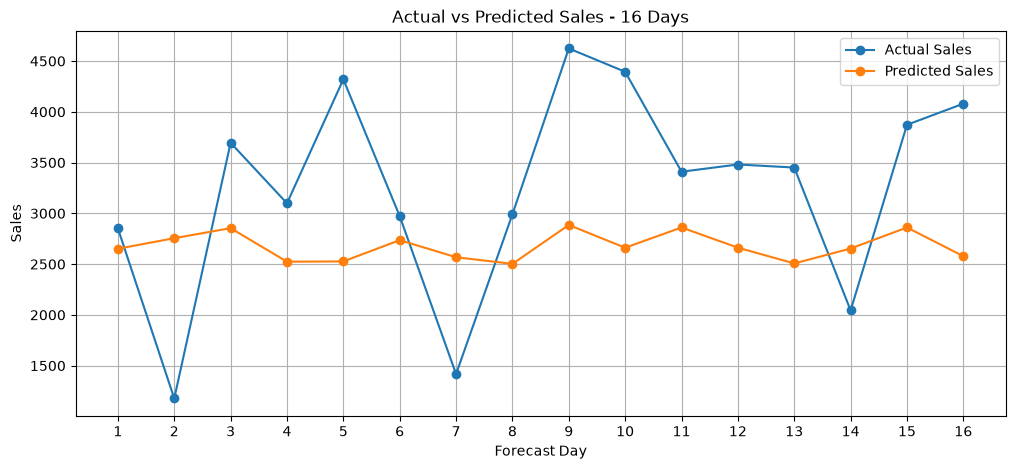

In [51]:
import matplotlib.pyplot as plt

# Select the first test sequence
actual = all_actuals_original[0]
predicted = all_predictions_original[0]

# Create day positions
days = range(1, len(actual) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    days,
    actual,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    days,
    predicted,
    marker="o",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales - 16 Days")
plt.xlabel("Forecast Day")
plt.ylabel("Sales")

plt.xticks(days)
plt.legend()
plt.grid(True)

plt.show()

In [53]:
# Extract the last observed scaled sales value
last_sales_scaled = X_test[:, -1, 0]

# Repeat it for all 16 forecast days
baseline_predictions_scaled = np.repeat(
    last_sales_scaled[:, np.newaxis],
    FORECAST_HORIZON,
    axis=1
)

print("Baseline predictions shape:",
      baseline_predictions_scaled.shape)

NameError: name 'FORECAST_HORIZON' is not defined

In [54]:
from src.config import FORECAST_HORIZON

print("Forecast horizon:", FORECAST_HORIZON)

Forecast horizon: 16


In [55]:
last_sales_scaled = X_test[:, -1, 0]

baseline_predictions_scaled = np.repeat(
    last_sales_scaled[:, np.newaxis],
    FORECAST_HORIZON,
    axis=1
)

print("Baseline predictions shape:",
      baseline_predictions_scaled.shape)

Baseline predictions shape: (239, 16)


In [56]:
baseline_predictions_original = sales_scaler.inverse_transform(
    baseline_predictions_scaled.reshape(-1, 1)
).reshape(baseline_predictions_scaled.shape)

print("Baseline predictions converted successfully!")

Baseline predictions converted successfully!


In [57]:
baseline_pred = baseline_predictions_original.flatten()

baseline_mae = mean_absolute_error(y_true, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_true, baseline_pred)
)

baseline_mape = np.mean(
    np.abs(
        (y_true[non_zero_mask] - baseline_pred[non_zero_mask])
        / y_true[non_zero_mask]
    )
) * 100

print("Naive Baseline Results")
print("----------------------")
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"MAPE: {baseline_mape:.2f}%")

Naive Baseline Results
----------------------
MAE:  885.50
RMSE: 1212.20
MAPE: 42.33%


In [58]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Naive Baseline": [
        baseline_mae,
        baseline_rmse,
        baseline_mape
    ],
    "LSTM": [
        mae,
        rmse,
        mape
    ]
})

comparison["Improvement (%)"] = (
    (comparison["Naive Baseline"] - comparison["LSTM"])
    / comparison["Naive Baseline"]
) * 100

print(comparison.round(2))

  Metric  Naive Baseline    LSTM  Improvement (%)
0    MAE          885.50  696.34            21.36
1   RMSE         1212.20  886.04            26.91
2   MAPE           42.33   32.91            22.26


In [59]:
comparison.to_csv(
    "artifacts/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

OSError: Cannot save file into a non-existent directory: 'artifacts'

In [60]:
from pathlib import Path

# Get the main project directory
PROJECT_ROOT = Path.cwd().parent

# Get artifacts directory
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

# Create directory if it doesn't exist
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Artifacts directory:", ARTIFACT_DIR)
print("Directory exists:", ARTIFACT_DIR.exists())

Artifacts directory: c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\artifacts
Directory exists: True


In [61]:
comparison.to_csv(
    ARTIFACT_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [62]:
print(list(ARTIFACT_DIR.iterdir()))

[WindowsPath('c:/Users/Anshika Singh/Desktop/ai-sales-forecasting/artifacts/model_comparison.csv')]


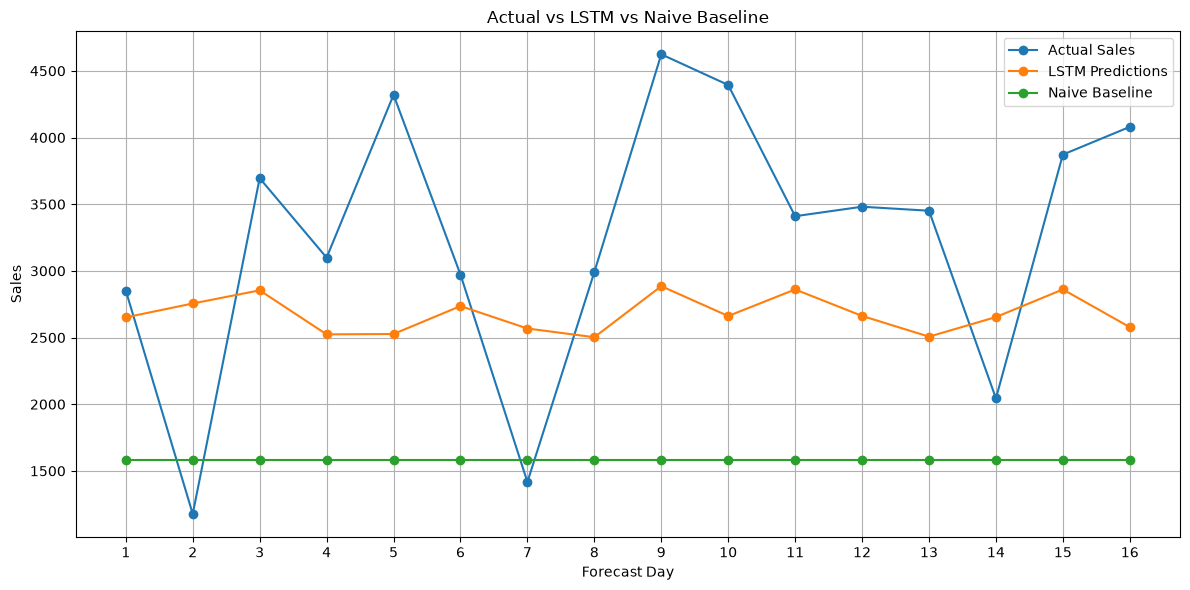

In [63]:
import matplotlib.pyplot as plt

# Select the first test sequence
actual = all_actuals_original[0]
lstm_pred = all_predictions_original[0]
baseline_pred = baseline_predictions_original[0]

days = range(1, FORECAST_HORIZON + 1)

plt.figure(figsize=(12, 6))

plt.plot(days, actual, marker="o", label="Actual Sales")
plt.plot(days, lstm_pred, marker="o", label="LSTM Predictions")
plt.plot(days, baseline_pred, marker="o", label="Naive Baseline")

plt.title("Actual vs LSTM vs Naive Baseline")
plt.xlabel("Forecast Day")
plt.ylabel("Sales")

plt.xticks(days)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate absolute error for every prediction
absolute_errors = np.abs(
    all_actuals_original - all_predictions_original
)

# Calculate squared error for every prediction
squared_errors = (
    all_actuals_original - all_predictions_original
) ** 2

# Calculate MAE for each forecast day
day_mae = np.mean(absolute_errors, axis=0)

# Calculate RMSE for each forecast day
day_rmse = np.sqrt(
    np.mean(squared_errors, axis=0)
)

# Create a results DataFrame
horizon_results = pd.DataFrame({
    "Forecast Day": np.arange(1, FORECAST_HORIZON + 1),
    "MAE": day_mae,
    "RMSE": day_rmse
})

print(horizon_results.round(2))


    Forecast Day         MAE        RMSE
0              1  724.719971  903.080017
1              2  691.429993  889.679993
2              3  662.619995  874.039978
3              4  765.650024  922.859985
4              5  749.710022  913.219971
5              6  660.369995  864.270020
6              7  730.900024  900.719971
7              8  760.969971  920.840027
8              9  639.780029  869.039978
9             10  701.390015  882.669983
10            11  614.909973  847.059998
11            12  680.909973  868.059998
12            13  721.549988  886.690002
13            14  686.049988  874.919983
14            15  643.020020  869.820007
15            16  707.440002  885.789978


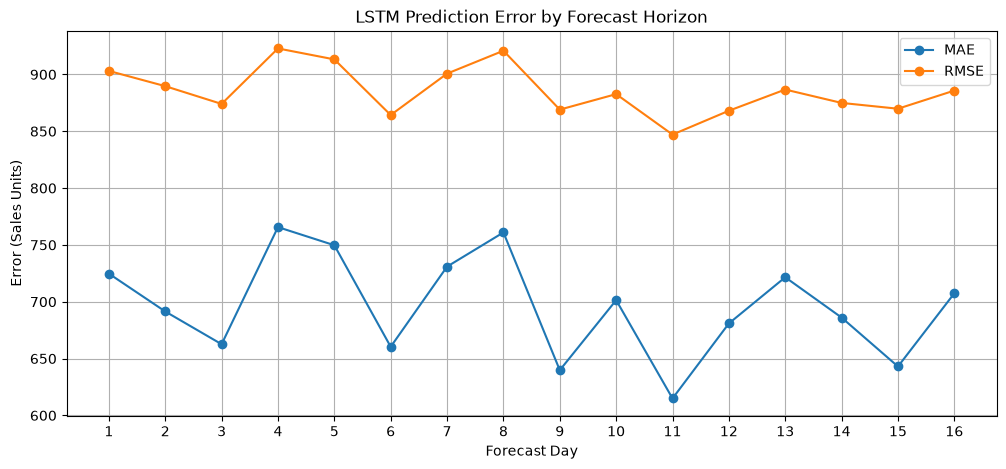

In [65]:

plt.figure(figsize=(12, 5))

plt.plot(
    horizon_results["Forecast Day"],
    horizon_results["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    horizon_results["Forecast Day"],
    horizon_results["RMSE"],
    marker="o",
    label="RMSE"
)

plt.title("LSTM Prediction Error by Forecast Horizon")
plt.xlabel("Forecast Day")
plt.ylabel("Error (Sales Units)")
plt.xticks(range(1, FORECAST_HORIZON + 1))
plt.legend()
plt.grid(True)
plt.show()


In [66]:

import numpy as np
import pandas as pd

# Calculate the starting index of test data
test_start_index = 1181 + 253

# Extract test dates
test_dates = (
    model_df["date"]
    .iloc[test_start_index:]
    .reset_index(drop=True)
)

# Extract test promotion counts
test_promotions = (
    model_df["onpromotion"]
    .iloc[test_start_index:]
    .reset_index(drop=True)
)

# Create 16-day date windows
target_dates = np.array([
    test_dates.iloc[i:i + FORECAST_HORIZON].to_numpy()
    for i in range(len(test_dates) - FORECAST_HORIZON + 1)
])

# Create 16-day promotion windows
target_promotions = np.array([
    test_promotions.iloc[i:i + FORECAST_HORIZON].to_numpy()
    for i in range(len(test_promotions) - FORECAST_HORIZON + 1)
])

print("Target dates shape:", target_dates.shape)
print("Target promotions shape:", target_promotions.shape)
print("Predictions shape:", all_predictions_original.shape)
print("Actuals shape:", all_actuals_original.shape)


Target dates shape: (239, 16)
Target promotions shape: (239, 16)
Predictions shape: (239, 16)
Actuals shape: (239, 16)


In [67]:

# Create a DataFrame containing all prediction information
analysis_df = pd.DataFrame({
    "date": target_dates.flatten(),
    "actual_sales": all_actuals_original.flatten(),
    "predicted_sales": all_predictions_original.flatten(),
    "onpromotion": target_promotions.flatten()
})

# Convert date into datetime format
analysis_df["date"] = pd.to_datetime(analysis_df["date"])

# Calculate absolute prediction error
analysis_df["absolute_error"] = np.abs(
    analysis_df["actual_sales"] -
    analysis_df["predicted_sales"]
)

# Calculate squared prediction error
analysis_df["squared_error"] = (
    analysis_df["actual_sales"] -
    analysis_df["predicted_sales"]
) ** 2

# Extract weekday name
analysis_df["weekday"] = (
    analysis_df["date"].dt.day_name()
)

# Categorize promotion status
analysis_df["promotion_status"] = np.where(
    analysis_df["onpromotion"] > 0,
    "Promotion",
    "No Promotion"
)

# Display first 10 records
print(analysis_df.head(10))

# Display DataFrame shape
print("\nDataFrame Shape:", analysis_df.shape)


        date  actual_sales  predicted_sales  onpromotion  absolute_error  \
0 2016-12-05   2852.000000      2651.347168         93.0      200.652832   
1 2016-12-06   1177.000000      2755.312744         78.0     1578.312744   
2 2016-12-07   3695.000000      2854.026855        167.0      840.973145   
3 2016-12-08   3099.000000      2523.794434        117.0      575.205566   
4 2016-12-09   4320.000000      2526.561523        114.0     1793.438477   
5 2016-12-10   2971.999756      2736.022949        105.0      235.976807   
6 2016-12-11   1417.000000      2567.814209         92.0     1150.814209   
7 2016-12-12   2991.000000      2502.350342        114.0      488.649658   
8 2016-12-13   4624.000000      2885.354980        108.0     1738.645020   
9 2016-12-14   4394.000000      2661.433594        109.0     1732.566406   

   squared_error    weekday promotion_status  
0   4.026156e+04     Monday        Promotion  
1   2.491071e+06    Tuesday        Promotion  
2   7.072358e+05  Wedn

In [68]:

weekday_results = (
    analysis_df
    .groupby("weekday")
    .agg(
        MAE=("absolute_error", "mean"),

        RMSE=(
            "squared_error",
            lambda x: np.sqrt(x.mean())
        ),

        Average_Actual_Sales=("actual_sales", "mean"),

        Total_Records=("actual_sales", "count")
    )
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

print(weekday_results.round(2))


                   MAE         RMSE  Average_Actual_Sales  Total_Records
weekday                                                                 
Monday      580.409973   766.340027           2659.320068            547
Tuesday     645.619995   891.909973           3042.290039            547
Wednesday   812.979980   940.679993           3283.770020            546
Thursday    349.000000   535.919983           2756.409912            546
Friday      711.140015   854.340027           3004.520020            546
Saturday    473.079987   576.570007           2860.699951            546
Sunday     1302.449951  1370.640015           1174.609985            546


In [69]:

promotion_results = (
    analysis_df
    .groupby("promotion_status")
    .agg(
        MAE=("absolute_error", "mean"),

        RMSE=(
            "squared_error",
            lambda x: np.sqrt(x.mean())
        ),

        Average_Actual_Sales=("actual_sales", "mean"),

        Average_Promotions=("onpromotion", "mean"),

        Total_Records=("actual_sales", "count")
    )
)

print(promotion_results.round(2))


                          MAE        RMSE  Average_Actual_Sales  \
promotion_status                                                  
No Promotion      2768.479980  2773.47998              0.000000   
Promotion          678.849976   852.52002           2705.820068   

                  Average_Promotions  Total_Records  
promotion_status                                     
No Promotion                    0.00             32  
Promotion                      51.64           3792  


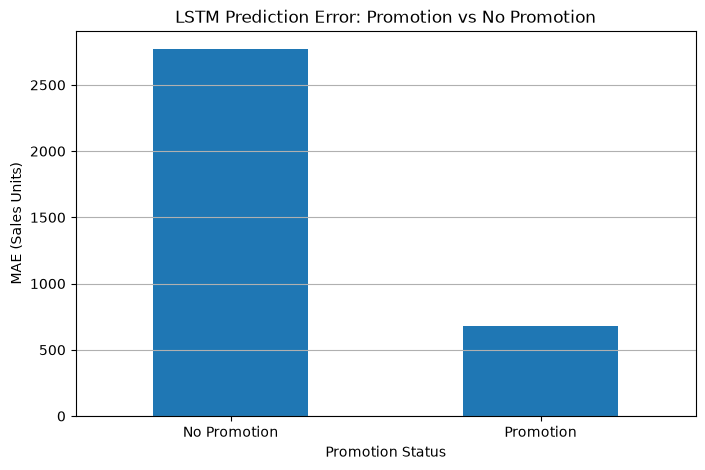

In [70]:

promotion_results["MAE"].plot(
    kind="bar",
    figsize=(8, 5),
    title="LSTM Prediction Error: Promotion vs No Promotion"
)

plt.xlabel("Promotion Status")
plt.ylabel("MAE (Sales Units)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()


In [71]:

# Inspect records where no promotion was recorded
no_promotion_df = analysis_df[
    analysis_df["promotion_status"] == "No Promotion"
]

# Check the actual dates and sales
print(
    no_promotion_df.groupby("date").agg(
        Actual_Sales=("actual_sales", "mean"),
        Predicted_Sales=("predicted_sales", "mean"),
        Promotion_Count=("onpromotion", "first"),
        Record_Count=("date", "count")
    ).round(2)
)

print("\nUnique dates:", no_promotion_df["date"].nunique())
print("Total records:", len(no_promotion_df))


            Actual_Sales  Predicted_Sales  Promotion_Count  Record_Count
date                                                                    
2016-12-25           0.0      2780.310059              0.0            16
2017-01-01           0.0      2756.639893              0.0            16

Unique dates: 2
Total records: 32


In [72]:

# Inspect Christmas and New Year sales
holiday_dates = [
    "2016-12-25",
    "2017-01-01"
]

holiday_check = model_df[
    model_df["date"].isin(holiday_dates)
][["date", "sales", "onpromotion"]]

print(holiday_check)


Empty DataFrame
Columns: [date, sales, onpromotion]
Index: []


In [73]:

print("Date column data type:")
print(model_df["date"].dtype)

print("\nFirst date:")
print(model_df["date"].min())

print("\nLast date:")
print(model_df["date"].max())

print("\nTest data start:")
print(test_dates.min())

print("\nTest data end:")
print(test_dates.max())


Date column data type:
datetime64[us]

First date:
2013-01-01 00:00:00

Last date:
2017-08-15 00:00:00

Test data start:
2016-12-05 00:00:00

Test data end:
2017-08-15 00:00:00


In [74]:

model_df["date"] = pd.to_datetime(model_df["date"])

print(
    model_df[
        model_df["date"].isin(
            pd.to_datetime(["2016-12-25", "2017-01-01"])
        )
    ][["date", "sales", "onpromotion"]]
)


           date  sales  onpromotion
1454 2016-12-25    0.0          0.0
1461 2017-01-01    0.0          0.0


In [75]:
# Check the first five records
display(model_df.head())

# Check the last five records
display(model_df.tail())

# Check column names and data types
print(model_df.dtypes)

# Check dataset shape
print("Shape:", model_df.shape)

# Check missing values
print("\nMissing values:")
print(model_df.isnull().sum())

# Check date range
print("\nDate range:")
print("Start:", model_df["date"].min())
print("End:", model_df["date"].max())

# Check whether dates are continuous
print("\nNumber of unique dates:", model_df["date"].nunique())
print("Number of rows:", len(model_df))

,date,sales,onpromotion
0,2013-01-01,0.0,0.0
1,2013-01-02,2652.0,0.0
2,2013-01-03,2121.0,0.0
3,2013-01-04,2056.0,0.0
4,2013-01-05,2216.0,0.0


,date,sales,onpromotion
1683,2017-08-11,1270.0,24.0
1684,2017-08-12,1630.0,28.0
1685,2017-08-13,952.0,19.0
1686,2017-08-14,2407.0,30.0
1687,2017-08-15,2508.0,29.0


date           datetime64[us]
sales                 float64
onpromotion           float64
dtype: object
Shape: (1688, 3)

Missing values:
date           0
sales          0
onpromotion    0
dtype: int64

Date range:
Start: 2013-01-01 00:00:00
End: 2017-08-15 00:00:00

Number of unique dates: 1688
Number of rows: 1688


In [76]:
# Create a copy so our original dataset remains unchanged
feature_df = model_df.copy()

# Extract day of the week
feature_df["day_of_week"] = feature_df["date"].dt.dayofweek

# Check the result
display(feature_df[["date", "sales", "day_of_week"]].head(10))

C:\Users\Anshika Singh\AppData\Local\Temp\ipykernel_21468\2156227014.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  feature_df["day_of_week"] = feature_df["date"].dt.dayofweek


,date,sales,day_of_week
0,2013-01-01,0.0,1
1,2013-01-02,2652.0,2
2,2013-01-03,2121.0,3
3,2013-01-04,2056.0,4
4,2013-01-05,2216.0,5
5,2013-01-06,723.0,6
6,2013-01-07,2262.0,0
7,2013-01-08,1782.0,1
8,2013-01-09,2429.0,2
9,2013-01-10,1544.0,3


In [77]:
# Create weekend indicator
feature_df["is_weekend"] = (
    feature_df["day_of_week"] >= 5
).astype(int)

# Check the result
display(
    feature_df[
        ["date", "day_of_week", "is_weekend", "sales"]
    ].head(15)
)

,date,day_of_week,is_weekend,sales
0,2013-01-01,1,0,0.0
1,2013-01-02,2,0,2652.0
2,2013-01-03,3,0,2121.0
3,2013-01-04,4,0,2056.0
4,2013-01-05,5,1,2216.0
5,2013-01-06,6,1,723.0
6,2013-01-07,0,0,2262.0
7,2013-01-08,1,0,1782.0
8,2013-01-09,2,0,2429.0
9,2013-01-10,3,0,1544.0


In [78]:
# Average sales by weekday
weekday_sales = (
    feature_df.groupby("day_of_week")["sales"]
    .mean()
)

print("Average sales by weekday:")
print(weekday_sales)

# Average sales by weekend vs weekday
weekend_sales = (
    feature_df.groupby("is_weekend")["sales"]
    .mean()
)

print("\nAverage sales: Weekday vs Weekend")
print(weekend_sales)

Average sales by weekday:
day_of_week
0    2383.493776
1    2408.991736
2    2758.867220
3    2219.796680
4    2403.630705
5    2322.962656
6    1026.796680
Name: sales, dtype: float64

Average sales: Weekday vs Weekend
is_weekend
0    2434.934494
1    1674.879668
Name: sales, dtype: float64


In [79]:
holidays_df = pd.read_csv(
    RAW_DATA_DIR / "holidays_events.csv"
)

print("Shape:", holidays_df.shape)
print("\nColumns:")
print(holidays_df.columns.tolist())

display(holidays_df.head(10))

NameError: name 'RAW_DATA_DIR' is not defined

In [80]:
from src.config import RAW_DATA_DIR

In [81]:
import pandas as pd

holidays_df = pd.read_csv(
    RAW_DATA_DIR / "holidays_events.csv"
)

print("Shape:", holidays_df.shape)

print("\nColumns:")
print(holidays_df.columns.tolist())

display(holidays_df.head(10))

Shape: (350, 6)

Columns:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
6,2012-06-23,Holiday,Local,Guaranda,Cantonizacion de Guaranda,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False


In [82]:
stores_df = pd.read_csv(RAW_DATA_DIR / "stores.csv")

store_info = stores_df[stores_df["store_nbr"] == 1]

display(store_info)

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13


In [83]:
# Convert holiday dates to datetime
holidays_df["date"] = pd.to_datetime(holidays_df["date"])

print("Holiday types:")
print(holidays_df["type"].unique())

print("\nHoliday locations:")
print(holidays_df["locale"].unique())

print("\nLocale names:")
print(holidays_df["locale_name"].unique())

print("\nTransferred holiday counts:")
print(holidays_df["transferred"].value_counts())

Holiday types:
<StringArray>
['Holiday', 'Transfer', 'Additional', 'Bridge', 'Work Day', 'Event']
Length: 6, dtype: str

Holiday locations:
<StringArray>
['Local', 'Regional', 'National']
Length: 3, dtype: str

Locale names:
<StringArray>
[                         'Manta',                       'Cotopaxi',
                         'Cuenca',                       'Libertad',
                       'Riobamba',                           'Puyo',
                       'Guaranda',                       'Imbabura',
                      'Latacunga',                        'Machala',
                  'Santo Domingo',                      'El Carmen',
                        'Cayambe',                     'Esmeraldas',
                        'Ecuador',                         'Ambato',
                         'Ibarra',                        'Quevedo',
 'Santo Domingo de los Tsachilas',                    'Santa Elena',
                          'Quito',                           'Loja',
  

In [84]:
# Store 1 location
STORE_CITY = "Quito"
STORE_STATE = "Pichincha"

# Holiday types that we want to include
holiday_types = [
    "Holiday",
    "Transfer",
    "Additional",
    "Bridge"
]

# Select holidays applicable to Store 1
store_holidays = holidays_df[
    (
        (holidays_df["locale"] == "National") &
        (holidays_df["locale_name"] == "Ecuador")
    ) |
    (
        (holidays_df["locale"] == "Regional") &
        (holidays_df["locale_name"] == STORE_STATE)
    ) |
    (
        (holidays_df["locale"] == "Local") &
        (holidays_df["locale_name"] == STORE_CITY)
    )
].copy()

# Exclude moved-away original holidays and non-holiday types
store_holidays = store_holidays[
    (store_holidays["type"].isin(holiday_types)) &
    (store_holidays["transferred"] == False)
]

# Get unique holiday dates
holiday_dates = store_holidays["date"].drop_duplicates()

# Create holiday indicator
feature_df["is_holiday"] = (
    feature_df["date"].isin(holiday_dates)
).astype(int)

# Inspect results
print("Applicable holiday records:", len(store_holidays))
print("Unique holiday dates:", holiday_dates.nunique())

display(
    feature_df[
        feature_df["is_holiday"] == 1
    ][["date", "sales", "is_holiday"]].head(20)
)

Applicable holiday records: 117
Unique holiday dates: 114


,date,sales,is_holiday
0,2013-01-01,0.0,1
41,2013-02-11,458.0,1
42,2013-02-12,628.0,1
118,2013-04-29,1579.0,1
120,2013-05-01,966.0,1
130,2013-05-11,2244.0,1
143,2013-05-24,650.0,1
221,2013-08-10,1315.0,1
283,2013-10-11,1239.0,1
305,2013-11-02,1894.0,1


In [85]:
check_dates = pd.to_datetime([
    "2016-12-25",
    "2017-01-01"
])

display(
    feature_df[
        feature_df["date"].isin(check_dates)
    ][["date", "sales", "is_holiday"]]
)

,date,sales,is_holiday
1454,2016-12-25,0.0,1
1461,2017-01-01,0.0,0


In [86]:
print("Holiday feature distribution:")
print(feature_df["is_holiday"].value_counts())

print("\nAverage sales on holidays vs non-holidays:")
print(
    feature_df.groupby("is_holiday")["sales"].mean()
)

Holiday feature distribution:
is_holiday
0    1598
1      90
Name: count, dtype: int64

Average sales on holidays vs non-holidays:
is_holiday
0    2250.531289
1    1638.600000
Name: sales, dtype: float64


In [87]:
dates_to_check = pd.to_datetime([
    "2016-12-25",
    "2017-01-01",
    "2017-01-02"
])

display(
    holidays_df[
        holidays_df["date"].isin(dates_to_check)
    ][
        [
            "date",
            "type",
            "locale",
            "locale_name",
            "description",
            "transferred"
        ]
    ].sort_values("date")
)

,date,type,locale,locale_name,description,transferred
294,2016-12-25,Holiday,National,Ecuador,Navidad,False
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
298,2017-01-02,Transfer,National,Ecuador,Traslado Primer dia del ano,False


In [88]:
model_features = [
    "sales_scaled",
    "promotion_scaled",
    "day_of_week",
    "is_weekend",
    "is_holiday"
]

In [89]:
check_dates = pd.to_datetime([
    "2016-12-25",
    "2017-01-01",
    "2017-01-02"
])

display(
    feature_df[
        feature_df["date"].isin(check_dates)
    ][["date", "sales", "is_holiday"]]
)

,date,sales,is_holiday
1454,2016-12-25,0.0,1
1461,2017-01-01,0.0,0
1462,2017-01-02,1218.0,1


In [90]:
print("Dataset shape:", feature_df.shape)

print("\nColumns:")
print(feature_df.columns.tolist())

print("\nData types:")
print(feature_df.dtypes)

print("\nMissing values:")
print(feature_df.isnull().sum())

display(feature_df.head(10))

Dataset shape: (1688, 6)

Columns:
['date', 'sales', 'onpromotion', 'day_of_week', 'is_weekend', 'is_holiday']

Data types:
date           datetime64[us]
sales                 float64
onpromotion           float64
day_of_week             int32
is_weekend              int64
is_holiday              int64
dtype: object

Missing values:
date           0
sales          0
onpromotion    0
day_of_week    0
is_weekend     0
is_holiday     0
dtype: int64


,date,sales,onpromotion,day_of_week,is_weekend,is_holiday
0,2013-01-01,0.0,0.0,1,0,1
1,2013-01-02,2652.0,0.0,2,0,0
2,2013-01-03,2121.0,0.0,3,0,0
3,2013-01-04,2056.0,0.0,4,0,0
4,2013-01-05,2216.0,0.0,5,1,0
5,2013-01-06,723.0,0.0,6,1,0
6,2013-01-07,2262.0,0.0,0,0,0
7,2013-01-08,1782.0,0.0,1,0,0
8,2013-01-09,2429.0,0.0,2,0,0
9,2013-01-10,1544.0,0.0,3,0,0


In [91]:
# Select model-related columns
feature_df = feature_df[
    [
        "date",
        "sales",
        "onpromotion",
        "day_of_week",
        "is_weekend",
        "is_holiday"
    ]
].copy()

# Sort chronologically
feature_df = feature_df.sort_values("date").reset_index(drop=True)

# Verify
print("Dataset shape:", feature_df.shape)

print("\nMissing values:")
print(feature_df.isnull().sum())

display(feature_df.head())

Dataset shape: (1688, 6)

Missing values:
date           0
sales          0
onpromotion    0
day_of_week    0
is_weekend     0
is_holiday     0
dtype: int64


,date,sales,onpromotion,day_of_week,is_weekend,is_holiday
0,2013-01-01,0.0,0.0,1,0,1
1,2013-01-02,2652.0,0.0,2,0,0
2,2013-01-03,2121.0,0.0,3,0,0
3,2013-01-04,2056.0,0.0,4,0,0
4,2013-01-05,2216.0,0.0,5,1,0


In [92]:
import pandas as pd

# Generate next 16 dates
future_dates = pd.date_range(
    start=feature_df["date"].max() + pd.Timedelta(days=1),
    periods=16,
    freq="D"
)

# Create future calendar dataframe
future_df = pd.DataFrame({
    "date": future_dates
})

# Extract weekday
future_df["day_of_week"] = future_df["date"].dt.dayofweek

# Identify weekends
future_df["is_weekend"] = (
    future_df["day_of_week"] >= 5
).astype(int)

# Identify holidays using our existing holiday calendar
future_df["is_holiday"] = (
    future_df["date"].isin(holiday_dates)
).astype(int)

display(future_df)

C:\Users\Anshika Singh\AppData\Local\Temp\ipykernel_21468\2366673898.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  future_df["day_of_week"] = future_df["date"].dt.dayofweek


,date,day_of_week,is_weekend,is_holiday
0,2017-08-16,2,0,0
1,2017-08-17,3,0,0
2,2017-08-18,4,0,0
3,2017-08-19,5,1,0
4,2017-08-20,6,1,0
5,2017-08-21,0,0,0
6,2017-08-22,1,0,0
7,2017-08-23,2,0,0
8,2017-08-24,3,0,0
9,2017-08-25,4,0,0


In [93]:
import numpy as np

# Convert weekday into cyclical features
feature_df["day_of_week_sin"] = np.sin(
    2 * np.pi * feature_df["day_of_week"] / 7
)

feature_df["day_of_week_cos"] = np.cos(
    2 * np.pi * feature_df["day_of_week"] / 7
)

# Apply the same transformation to future dates
future_df["day_of_week_sin"] = np.sin(
    2 * np.pi * future_df["day_of_week"] / 7
)

future_df["day_of_week_cos"] = np.cos(
    2 * np.pi * future_df["day_of_week"] / 7
)

display(
    feature_df[
        ["date", "day_of_week", "day_of_week_sin",
         "day_of_week_cos"]
    ].head(10)
)

,date,day_of_week,day_of_week_sin,day_of_week_cos
0,2013-01-01,1,0.781831,0.623490
1,2013-01-02,2,0.974928,-0.222521
2,2013-01-03,3,0.433884,-0.900969
3,2013-01-04,4,-0.433884,-0.900969
4,2013-01-05,5,-0.974928,-0.222521
5,2013-01-06,6,-0.781831,0.623490
6,2013-01-07,0,0.000000,1.000000
7,2013-01-08,1,0.781831,0.623490
8,2013-01-09,2,0.974928,-0.222521
9,2013-01-10,3,0.433884,-0.900969


In [94]:
# Define historical input features
HISTORICAL_FEATURES = [
    "sales_scaled",
    "promotion_scaled",
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend",
    "is_holiday"
]

# Define future calendar features
FUTURE_FEATURES = [
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend",
    "is_holiday"
]

# Define target
TARGET = "sales_scaled"

print("Historical features:", HISTORICAL_FEATURES)
print("Number of historical features:", len(HISTORICAL_FEATURES))

print("\nFuture features:", FUTURE_FEATURES)
print("Number of future features:", len(FUTURE_FEATURES))

Historical features: ['sales_scaled', 'promotion_scaled', 'day_of_week_sin', 'day_of_week_cos', 'is_weekend', 'is_holiday']
Number of historical features: 6

Future features: ['day_of_week_sin', 'day_of_week_cos', 'is_weekend', 'is_holiday']
Number of future features: 4


In [95]:
# Calculate split boundaries
train_end = int(len(feature_df) * 0.70)
val_end = train_end + int(len(feature_df) * 0.15)

# Chronological splits
train_df = feature_df.iloc[:train_end].copy()
val_df = feature_df.iloc[train_end:val_end].copy()
test_df = feature_df.iloc[val_end:].copy()

# Display split information
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nDate ranges:")
print("Training:", train_df["date"].min(), "to", train_df["date"].max())
print("Validation:", val_df["date"].min(), "to", val_df["date"].max())
print("Testing:", test_df["date"].min(), "to", test_df["date"].max())

Training: (1181, 8)
Validation: (253, 8)
Testing: (254, 8)

Date ranges:
Training: 2013-01-01 00:00:00 to 2016-03-26 00:00:00
Validation: 2016-03-27 00:00:00 to 2016-12-04 00:00:00
Testing: 2016-12-05 00:00:00 to 2017-08-15 00:00:00


In [96]:
from sklearn.preprocessing import MinMaxScaler

# Create NEW scalers (preserve your original scalers)
new_sales_scaler = MinMaxScaler()
new_promotion_scaler = MinMaxScaler()

# Fit only on training data
new_sales_scaler.fit(train_df[["sales"]])
new_promotion_scaler.fit(train_df[["onpromotion"]])

# Create a copy of the complete dataset
scaled_df = feature_df.copy()

# Transform sales
scaled_df["sales_scaled"] = new_sales_scaler.transform(
    scaled_df[["sales"]]
)

# Transform promotions
scaled_df["promotion_scaled"] = new_promotion_scaler.transform(
    scaled_df[["onpromotion"]]
)

# Check results
display(
    scaled_df[
        [
            "date",
            "sales",
            "sales_scaled",
            "onpromotion",
            "promotion_scaled"
        ]
    ].head(10)
)

,date,sales,sales_scaled,onpromotion,promotion_scaled
0,2013-01-01,0.0,0.000000,0.0,0.0
1,2013-01-02,2652.0,0.591832,0.0,0.0
2,2013-01-03,2121.0,0.473332,0.0,0.0
3,2013-01-04,2056.0,0.458826,0.0,0.0
4,2013-01-05,2216.0,0.494532,0.0,0.0
5,2013-01-06,723.0,0.161348,0.0,0.0
6,2013-01-07,2262.0,0.504798,0.0,0.0
7,2013-01-08,1782.0,0.397679,0.0,0.0
8,2013-01-09,2429.0,0.542067,0.0,0.0
9,2013-01-10,1544.0,0.344566,0.0,0.0


In [97]:
print("Training sales scaled range:")
print(
    scaled_df.iloc[:train_end]["sales_scaled"].min(),
    scaled_df.iloc[:train_end]["sales_scaled"].max()
)

print("\nTraining promotion scaled range:")
print(
    scaled_df.iloc[:train_end]["promotion_scaled"].min(),
    scaled_df.iloc[:train_end]["promotion_scaled"].max()
)

print("\nMissing values:")
print(scaled_df.isnull().sum())

Training sales scaled range:
0.0 1.0

Training promotion scaled range:
0.0 1.0

Missing values:
date                0
sales               0
onpromotion         0
day_of_week         0
is_weekend          0
is_holiday          0
day_of_week_sin     0
day_of_week_cos     0
sales_scaled        0
promotion_scaled    0
dtype: int64


In [98]:
import numpy as np

LOOKBACK = 90
HORIZON = 16

HISTORICAL_FEATURES = [
    "sales_scaled",
    "promotion_scaled",
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend",
    "is_holiday"
]

FUTURE_FEATURES = [
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend",
    "is_holiday"
]

TARGET = "sales_scaled"


def create_improved_sequences(
    data,
    start_idx,
    end_idx,
    lookback=LOOKBACK,
    horizon=HORIZON
):

    X_history = []
    X_future = []
    y = []

    # Each target window must remain inside its split
    for target_start in range(
        max(start_idx, lookback),
        end_idx - horizon + 1
    ):

        # Previous 90 days
        history = data.iloc[
            target_start - lookback:target_start
        ][HISTORICAL_FEATURES].values

        # Next 16 days of known calendar features
        future = data.iloc[
            target_start:target_start + horizon
        ][FUTURE_FEATURES].values

        # Actual sales for next 16 days
        target = data.iloc[
            target_start:target_start + horizon
        ][TARGET].values

        X_history.append(history)
        X_future.append(future)
        y.append(target)

    return (
        np.array(X_history, dtype=np.float32),
        np.array(X_future, dtype=np.float32),
        np.array(y, dtype=np.float32)
    )

In [99]:
# Training sequences
X_train_hist, X_train_future, y_train_new = (
    create_improved_sequences(
        scaled_df,
        start_idx=0,
        end_idx=train_end
    )
)

# Validation sequences
X_val_hist, X_val_future, y_val_new = (
    create_improved_sequences(
        scaled_df,
        start_idx=train_end,
        end_idx=val_end
    )
)

# Testing sequences
X_test_hist, X_test_future, y_test_new = (
    create_improved_sequences(
        scaled_df,
        start_idx=val_end,
        end_idx=len(scaled_df)
    )
)

In [100]:
print("TRAINING")
print("Historical:", X_train_hist.shape)
print("Future:", X_train_future.shape)
print("Target:", y_train_new.shape)

print("\nVALIDATION")
print("Historical:", X_val_hist.shape)
print("Future:", X_val_future.shape)
print("Target:", y_val_new.shape)

print("\nTESTING")
print("Historical:", X_test_hist.shape)
print("Future:", X_test_future.shape)
print("Target:", y_test_new.shape)

TRAINING
Historical: (1076, 90, 6)
Future: (1076, 16, 4)
Target: (1076, 16)

VALIDATION
Historical: (238, 90, 6)
Future: (238, 16, 4)
Target: (238, 16)

TESTING
Historical: (239, 90, 6)
Future: (239, 16, 4)
Target: (239, 16)


In [101]:
import torch
from src.model import SalesLSTM

# Create model
model = SalesLSTM(
    historical_input_size=6,
    future_input_size=4
)

# Take one training batch
history_sample = torch.tensor(
    X_train_hist[:32],
    dtype=torch.float32
)

future_sample = torch.tensor(
    X_train_future[:32],
    dtype=torch.float32
)

# Forward pass
predictions = model(
    history_sample,
    future_sample
)

print("Historical input:", history_sample.shape)
print("Future input:", future_sample.shape)
print("Predictions:", predictions.shape)

TypeError: SalesLSTM.__init__() got an unexpected keyword argument 'historical_input_size'

In [102]:
import importlib
import src.model

# Reload the updated model.py file
importlib.reload(src.model)

# Import the updated class
from src.model import SalesLSTM

In [103]:
model = SalesLSTM(
    historical_input_size=6,
    future_input_size=4
)

print(model)

SalesLSTM(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=64, out_features=16, bias=True)
)


In [104]:
history_sample = torch.tensor(
    X_train_hist[:32],
    dtype=torch.float32
)

future_sample = torch.tensor(
    X_train_future[:32],
    dtype=torch.float32
)

predictions = model(history_sample, future_sample)

print("Historical input:", history_sample.shape)
print("Future input:", future_sample.shape)
print("Predictions:", predictions.shape)

Historical input: torch.Size([32, 90, 6])
Future input: torch.Size([32, 16, 4])
Predictions: torch.Size([32, 16])


In [105]:

import torch
from torch.utils.data import Dataset, DataLoader


class ImprovedSalesDataset(Dataset):

    def __init__(self, X_history, X_future, y):

        self.X_history = torch.tensor(
            X_history,
            dtype=torch.float32
        )

        self.X_future = torch.tensor(
            X_future,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):

        return (
            self.X_history[index],
            self.X_future[index],
            self.y[index]
        )


In [106]:
train_dataset_new = ImprovedSalesDataset(
    X_train_hist,
    X_train_future,
    y_train_new
)

val_dataset_new = ImprovedSalesDataset(
    X_val_hist,
    X_val_future,
    y_val_new
)

test_dataset_new = ImprovedSalesDataset(
    X_test_hist,
    X_test_future,
    y_test_new
)

In [107]:
BATCH_SIZE = 32

train_loader_new = DataLoader(
    train_dataset_new,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_new = DataLoader(
    val_dataset_new,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_new = DataLoader(
    test_dataset_new,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [108]:
history_batch, future_batch, target_batch = next(
    iter(train_loader_new)
)

print("Historical batch:", history_batch.shape)
print("Future batch:", future_batch.shape)
print("Target batch:", target_batch.shape)

print("\nData types:")
print(history_batch.dtype)
print(future_batch.dtype)
print(target_batch.dtype)

Historical batch: torch.Size([32, 90, 6])
Future batch: torch.Size([32, 16, 4])
Target batch: torch.Size([32, 16])

Data types:
torch.float32
torch.float32
torch.float32


In [109]:
import torch
import torch.nn as nn
import torch.optim as optim

# Select CPU or GPU automatically
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move model to selected device
model = model.to(device)

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Selected device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Selected device: cpu
Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [110]:

def train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
):

    # Enable training mode
    model.train()

    total_loss = 0.0
    total_samples = 0

    for history_batch, future_batch, target_batch in train_loader:

        # Move batches to CPU/GPU
        history_batch = history_batch.to(device)
        future_batch = future_batch.to(device)
        target_batch = target_batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        predictions = model(
            history_batch,
            future_batch
        )

        # Calculate loss
        loss = criterion(
            predictions,
            target_batch
        )

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Accumulate loss
        batch_size = history_batch.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    average_loss = total_loss / total_samples

    return average_loss


In [111]:

def validate_one_epoch(
    model,
    val_loader,
    criterion,
    device
):

    # Enable evaluation mode
    model.eval()

    total_loss = 0.0
    total_samples = 0

    # Disable gradient calculations
    with torch.no_grad():

        for history_batch, future_batch, target_batch in val_loader:

            # Move batches to CPU/GPU
            history_batch = history_batch.to(device)
            future_batch = future_batch.to(device)
            target_batch = target_batch.to(device)

            # Forward propagation
            predictions = model(
                history_batch,
                future_batch
            )

            # Calculate validation loss
            loss = criterion(
                predictions,
                target_batch
            )

            batch_size = history_batch.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

    average_loss = total_loss / total_samples

    return average_loss


In [112]:
train_loss = train_one_epoch(
    model,
    train_loader_new,
    criterion,
    optimizer,
    device
)

val_loss = validate_one_epoch(
    model,
    val_loader_new,
    criterion,
    device
)

print("Training Loss:", train_loss)
print("Validation Loss:", val_loss)

Training Loss: 0.08874702232034676
Validation Loss: 0.05209687608881157


In [113]:
import torch
import torch.nn as nn
import torch.optim as optim

# Fresh model
model = SalesLSTM(
    historical_input_size=6,
    future_input_size=4
).to(device)

# Loss function
criterion = nn.MSELoss()

# Fresh optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Fresh model initialized successfully!")

Fresh model initialized successfully!


In [114]:
EPOCHS = 50
PATIENCE = 7

best_val_loss = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": []
}

MODEL_PATH = "models/improved_best_lstm_model.pth"

In [115]:

for epoch in range(EPOCHS):

    # Training
    train_loss = train_one_epoch(
        model,
        train_loader_new,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss = validate_one_epoch(
        model,
        val_loader_new,
        criterion,
        device
    )

    # Store losses
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # Display progress
    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

    # Check whether validation improved
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        # Save best model
        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print("Best model saved!")

    else:

        patience_counter += 1

        print(
            f"No improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

    # Early stopping
    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break


print("\nTraining completed!")
print("Best validation loss:", best_val_loss)


Epoch [1/50] Train Loss: 0.089412 Val Loss: 0.049294
Best model saved!
Epoch [2/50] Train Loss: 0.026621 Val Loss: 0.040791
Best model saved!
Epoch [3/50] Train Loss: 0.021921 Val Loss: 0.040243
Best model saved!
Epoch [4/50] Train Loss: 0.019496 Val Loss: 0.033761
Best model saved!
Epoch [5/50] Train Loss: 0.018519 Val Loss: 0.034632
No improvement: 1/7
Epoch [6/50] Train Loss: 0.016751 Val Loss: 0.030108
Best model saved!
Epoch [7/50] Train Loss: 0.015715 Val Loss: 0.030608
No improvement: 1/7
Epoch [8/50] Train Loss: 0.014717 Val Loss: 0.028585
Best model saved!
Epoch [9/50] Train Loss: 0.014470 Val Loss: 0.028120
Best model saved!
Epoch [10/50] Train Loss: 0.013971 Val Loss: 0.027407
Best model saved!
Epoch [11/50] Train Loss: 0.013610 Val Loss: 0.027346
Best model saved!
Epoch [12/50] Train Loss: 0.013274 Val Loss: 0.027545
No improvement: 1/7
Epoch [13/50] Train Loss: 0.012924 Val Loss: 0.026699
Best model saved!
Epoch [14/50] Train Loss: 0.012714 Val Loss: 0.028671
No improvemen

In [116]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best improved model loaded successfully!")

Best improved model loaded successfully!


In [117]:
import numpy as np

model.eval()

all_predictions_new = []
all_actuals_new = []

with torch.no_grad():

    for history_batch, future_batch, target_batch in test_loader_new:

        history_batch = history_batch.to(device)
        future_batch = future_batch.to(device)

        predictions = model(
            history_batch,
            future_batch
        )

        all_predictions_new.append(
            predictions.cpu().numpy()
        )

        all_actuals_new.append(
            target_batch.numpy()
        )

# Combine batches
all_predictions_new = np.concatenate(
    all_predictions_new,
    axis=0
)

all_actuals_new = np.concatenate(
    all_actuals_new,
    axis=0
)

print("Predictions shape:", all_predictions_new.shape)
print("Actual values shape:", all_actuals_new.shape)

Predictions shape: (239, 16)
Actual values shape: (239, 16)


In [118]:
all_predictions_original_new = new_sales_scaler.inverse_transform(
    all_predictions_new.reshape(-1, 1)
).reshape(all_predictions_new.shape)

all_actuals_original_new = new_sales_scaler.inverse_transform(
    all_actuals_new.reshape(-1, 1)
).reshape(all_actuals_new.shape)

In [119]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = all_actuals_original_new.flatten()
y_pred = all_predictions_original_new.flatten()

mae_new = mean_absolute_error(y_true, y_pred)

rmse_new = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

# MAPE excludes actual zero-sales observations
nonzero_mask = y_true != 0

mape_new = np.mean(
    np.abs(
        (y_true[nonzero_mask] - y_pred[nonzero_mask])
        / y_true[nonzero_mask]
    )
) * 100

print("Improved LSTM Evaluation")
print("------------------------")
print("MAE:", round(mae_new, 2))
print("RMSE:", round(rmse_new, 2))
print("MAPE:", round(mape_new, 2), "%")

Improved LSTM Evaluation
------------------------
MAE: 365.83
RMSE: 547.22
MAPE: 14.84 %


In [120]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Original LSTM",
        "Improved LSTM"
    ],
    "MAE": [885.50, 696.34, mae_new],
    "RMSE": [1212.20, 886.04, rmse_new],
    "MAPE": [42.33, 32.91, mape_new]
})

comparison_df.to_csv(
    "artifacts/final_model_comparison.csv",
    index=False
)

comparison_df

OSError: Cannot save file into a non-existent directory: 'artifacts'

In [121]:
from pathlib import Path

# Create the artifacts directory if it doesn't exist
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison results
comparison_path = ARTIFACT_DIR / "final_model_comparison.csv"

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("File saved successfully!")
print("Location:", comparison_path)

File saved successfully!
Location: c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\artifacts\final_model_comparison.csv


In [122]:
print(comparison_path.exists())

True


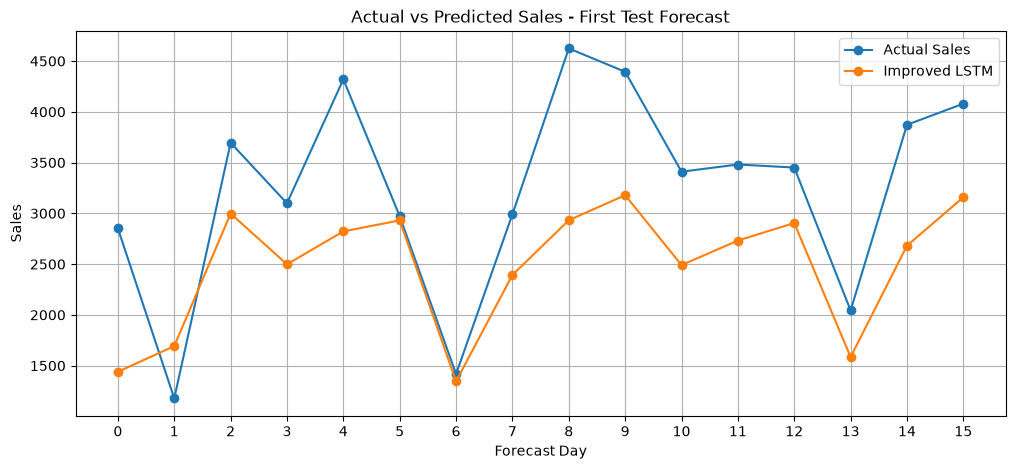

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    all_actuals_original_new[0],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    all_predictions_original_new[0],
    marker="o",
    label="Improved LSTM"
)

plt.title("Actual vs Predicted Sales - First Test Forecast")
plt.xlabel("Forecast Day")
plt.ylabel("Sales")
plt.xticks(range(16))
plt.legend()
plt.grid(True)

plt.show()

In [124]:
forecast_errors = np.abs(
    all_actuals_original_new - all_predictions_original_new
)

horizon_mae_new = forecast_errors.mean(axis=0)

for day, error in enumerate(horizon_mae_new, start=1):
    print(f"Forecast Day {day}: MAE = {error:.2f}")

Forecast Day 1: MAE = 387.98
Forecast Day 2: MAE = 350.55
Forecast Day 3: MAE = 362.25
Forecast Day 4: MAE = 367.01
Forecast Day 5: MAE = 354.11
Forecast Day 6: MAE = 368.79
Forecast Day 7: MAE = 375.82
Forecast Day 8: MAE = 368.87
Forecast Day 9: MAE = 341.94
Forecast Day 10: MAE = 352.62
Forecast Day 11: MAE = 359.44
Forecast Day 12: MAE = 382.51
Forecast Day 13: MAE = 359.30
Forecast Day 14: MAE = 382.25
Forecast Day 15: MAE = 374.82
Forecast Day 16: MAE = 365.07


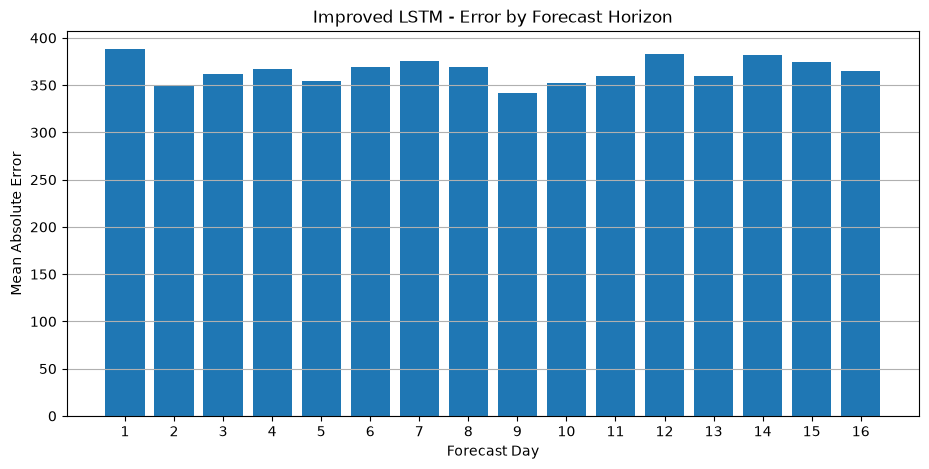

In [125]:
plt.figure(figsize=(11, 5))

plt.bar(
    range(1, 17),
    horizon_mae_new
)

plt.xlabel("Forecast Day")
plt.ylabel("Mean Absolute Error")
plt.title("Improved LSTM - Error by Forecast Horizon")
plt.xticks(range(1, 17))
plt.grid(axis="y")

plt.show()

In [126]:
original_horizon_mae = np.array([
    724.72, 691.43, 662.62, 765.65,
    749.71, 660.37, 730.90, 760.97,
    639.78, 701.39, 614.91, 680.91,
    721.55, 686.05, 643.02, 707.44
])

horizon_comparison = pd.DataFrame({
    "Forecast_Day": range(1, 17),
    "Original_LSTM_MAE": original_horizon_mae,
    "Improved_LSTM_MAE": horizon_mae_new
})

horizon_comparison["Improvement_Percentage"] = (
    (horizon_comparison["Original_LSTM_MAE"] -
     horizon_comparison["Improved_LSTM_MAE"])
    / horizon_comparison["Original_LSTM_MAE"]
) * 100

horizon_comparison.round(2)

,Forecast_Day,Original_LSTM_MAE,Improved_LSTM_MAE,Improvement_Percentage
0,1,724.72,387.980011,46.47
1,2,691.43,350.549988,49.30
2,3,662.62,362.250000,45.33
3,4,765.65,367.010010,52.07
4,5,749.71,354.109985,52.77
5,6,660.37,368.790009,44.15
6,7,730.90,375.820007,48.58
7,8,760.97,368.869995,51.53
8,9,639.78,341.940002,46.55
9,10,701.39,352.619995,49.73


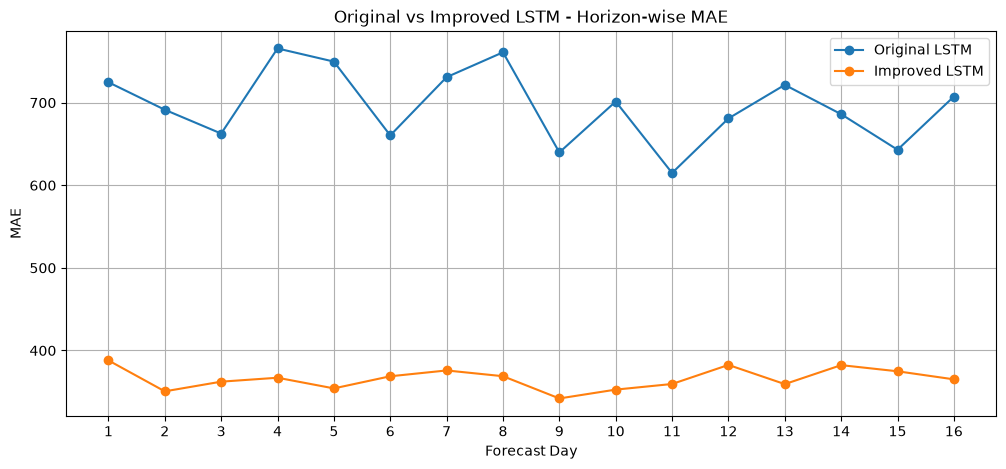

In [127]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 17),
    original_horizon_mae,
    marker="o",
    label="Original LSTM"
)

plt.plot(
    range(1, 17),
    horizon_mae_new,
    marker="o",
    label="Improved LSTM"
)

plt.xlabel("Forecast Day")
plt.ylabel("MAE")
plt.title("Original vs Improved LSTM - Horizon-wise MAE")
plt.xticks(range(1, 17))
plt.legend()
plt.grid(True)

plt.show()

In [128]:
# Recreate test dates
test_start_index = train_end + (val_end - train_end)

test_dates = (
    feature_df["date"]
    .iloc[val_end:]
    .reset_index(drop=True)
)

# Generate target dates for each test window
target_dates_new = np.array([
    test_dates.iloc[i:i + FORECAST_HORIZON].to_numpy()
    for i in range(len(test_dates) - FORECAST_HORIZON + 1)
])

# Flatten all values
weekday_analysis_df = pd.DataFrame({
    "date": target_dates_new.flatten(),
    "actual_sales": all_actuals_original_new.flatten(),
    "predicted_sales": all_predictions_original_new.flatten()
})

# Calculate errors
weekday_analysis_df["absolute_error"] = np.abs(
    weekday_analysis_df["actual_sales"]
    - weekday_analysis_df["predicted_sales"]
)

# Extract weekday
weekday_analysis_df["weekday"] = (
    pd.to_datetime(weekday_analysis_df["date"])
    .dt.day_name()
)

print(weekday_analysis_df.head())
print("Dataset shape:", weekday_analysis_df.shape)

        date  actual_sales  predicted_sales  absolute_error    weekday
0 2016-12-05        2852.0      1439.379028     1412.620972     Monday
1 2016-12-06        1177.0      1692.542114      515.542114    Tuesday
2 2016-12-07        3695.0      2997.436035      697.563965  Wednesday
3 2016-12-08        3099.0      2497.997314      601.002686   Thursday
4 2016-12-09        4320.0      2822.375732     1497.624268     Friday
Dataset shape: (3824, 5)


In [129]:
weekday_metrics_new = (
    weekday_analysis_df
    .groupby("weekday")
    .agg(
        MAE=("absolute_error", "mean"),
        Average_Actual_Sales=("actual_sales", "mean"),
        Total_Records=("absolute_error", "count")
    )
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

print(weekday_metrics_new.round(2))

                  MAE  Average_Actual_Sales  Total_Records
weekday                                                   
Monday     388.019989           2659.320068            547
Tuesday    453.950012           3042.290039            547
Wednesday  322.829987           3283.770020            546
Thursday   312.119995           2756.409912            546
Friday     465.910004           3004.520020            546
Saturday   398.970001           2860.699951            546
Sunday     218.830002           1174.609985            546


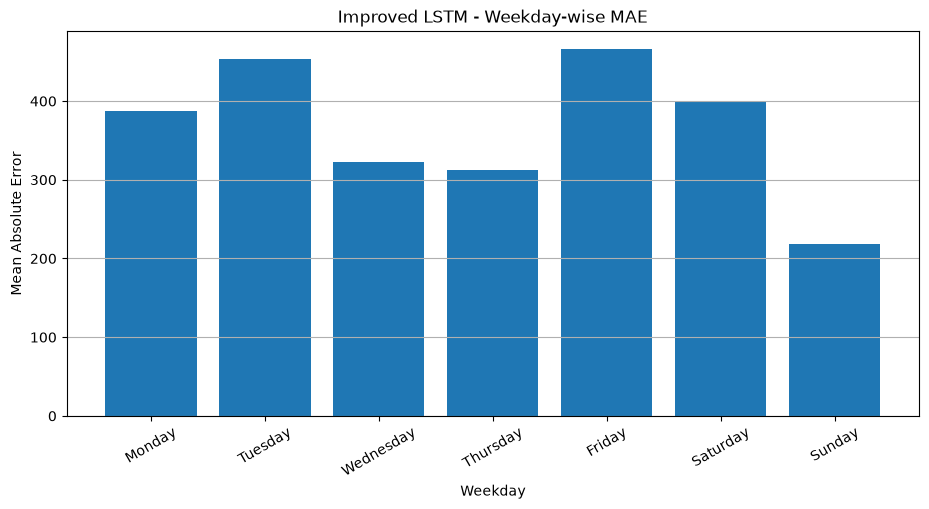

In [130]:
plt.figure(figsize=(11, 5))

plt.bar(
    weekday_metrics_new.index,
    weekday_metrics_new["MAE"]
)

plt.xlabel("Weekday")
plt.ylabel("Mean Absolute Error")
plt.title("Improved LSTM - Weekday-wise MAE")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

In [131]:
# Positive bias means overprediction
# Negative bias means underprediction

weekday_analysis_df["prediction_error"] = (
    weekday_analysis_df["predicted_sales"]
    - weekday_analysis_df["actual_sales"]
)

# Calculate overall bias
mean_bias = weekday_analysis_df["prediction_error"].mean()

print("Overall Mean Prediction Error:", round(mean_bias, 2))

if mean_bias > 0:
    print("Model generally OVERPREDICTS sales.")

elif mean_bias < 0:
    print("Model generally UNDERPREDICTS sales.")

else:
    print("Model has approximately zero average bias.")

Overall Mean Prediction Error: -151.2
Model generally UNDERPREDICTS sales.


In [132]:
bias_analysis = (
    weekday_analysis_df
    .groupby("weekday")
    .agg(
        Mean_Bias=("prediction_error", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

print(bias_analysis.round(2))

            Mean_Bias         MAE
weekday                          
Monday     -25.090000  388.019989
Tuesday   -282.359985  453.950012
Wednesday -142.110001  322.829987
Thursday  -185.429993  312.119995
Friday    -274.179993  465.910004
Saturday  -269.220001  398.970001
Sunday     120.029999  218.830002


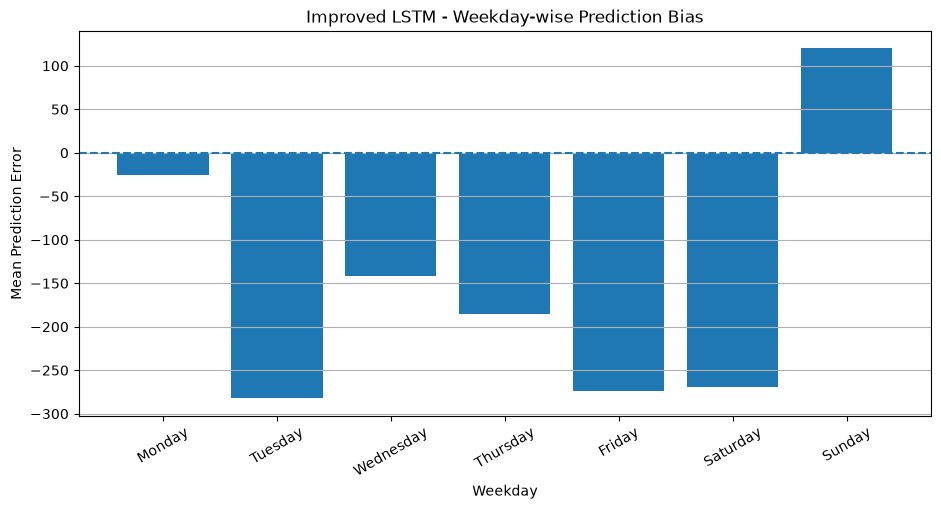

In [133]:
plt.figure(figsize=(11, 5))

plt.bar(
    bias_analysis.index,
    bias_analysis["Mean_Bias"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Weekday")
plt.ylabel("Mean Prediction Error")
plt.title("Improved LSTM - Weekday-wise Prediction Bias")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

In [134]:
fixed_history = scaled_df.iloc[
    val_end - LOOKBACK:val_end
][HISTORICAL_FEATURES].values

fixed_future = scaled_df.iloc[
    val_end:val_end + FORECAST_HORIZON
][FUTURE_FEATURES].values

fixed_actual = scaled_df.iloc[
    val_end:val_end + FORECAST_HORIZON
][TARGET].values

print("History:", fixed_history.shape)
print("Future:", fixed_future.shape)
print("Actual:", fixed_actual.shape)

History: (90, 6)
Future: (16, 4)
Actual: (16,)


In [135]:
fixed_history_tensor = torch.tensor(
    fixed_history,
    dtype=torch.float32
).unsqueeze(0).to(device)

fixed_future_tensor = torch.tensor(
    fixed_future,
    dtype=torch.float32
).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():

    fixed_predictions_scaled = model(
        fixed_history_tensor,
        fixed_future_tensor
    ).cpu().numpy()

print("Prediction shape:", fixed_predictions_scaled.shape)

Prediction shape: (1, 16)


In [136]:
fixed_predictions = new_sales_scaler.inverse_transform(
    fixed_predictions_scaled.reshape(-1, 1)
).flatten()

fixed_actual_original = new_sales_scaler.inverse_transform(
    fixed_actual.reshape(-1, 1)
).flatten()

fixed_mae = mean_absolute_error(
    fixed_actual_original,
    fixed_predictions
)

fixed_rmse = np.sqrt(
    mean_squared_error(
        fixed_actual_original,
        fixed_predictions
    )
)

print("Fixed 16-Day MAE:", round(fixed_mae, 2))
print("Fixed 16-Day RMSE:", round(fixed_rmse, 2))

Fixed 16-Day MAE: 820.59
Fixed 16-Day RMSE: 943.36


In [137]:
print(
    "First rolling MAE:",
    round(
        mean_absolute_error(
            all_actuals_original_new[0],
            all_predictions_original_new[0]
        ),
        2
    )
)

print(
    "Fixed forecast MAE:",
    round(fixed_mae, 2)
)

print(
    "Predictions match:",
    np.allclose(
        all_predictions_original_new[0],
        fixed_predictions,
        atol=1e-4
    )
)

First rolling MAE: 820.59
Fixed forecast MAE: 820.59
Predictions match: True


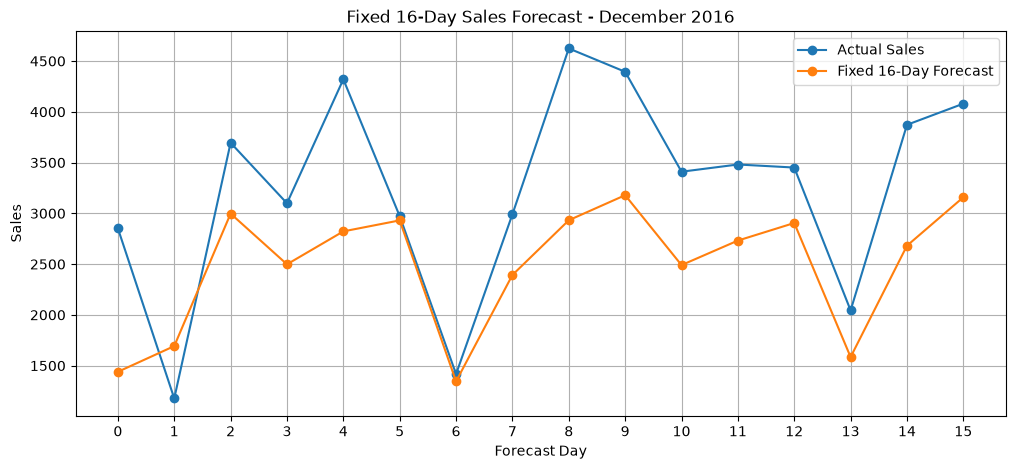

In [138]:
plt.figure(figsize=(12, 5))

plt.plot(
    fixed_actual_original,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    fixed_predictions,
    marker="o",
    label="Fixed 16-Day Forecast"
)

plt.xlabel("Forecast Day")
plt.ylabel("Sales")
plt.title("Fixed 16-Day Sales Forecast - December 2016")
plt.xticks(range(16))
plt.legend()
plt.grid(True)

plt.show()

In [139]:
residuals = (
    all_actuals_original_new
    - all_predictions_original_new
)

print("Residual shape:", residuals.shape)

print("Mean residual:", round(residuals.mean(), 2))

print("Standard deviation:", round(residuals.std(), 2))

print("Minimum residual:", round(residuals.min(), 2))

print("Maximum residual:", round(residuals.max(), 2))

Residual shape: (239, 16)
Mean residual: 151.2
Standard deviation: 525.92
Minimum residual: -2133.05
Maximum residual: 3144.49


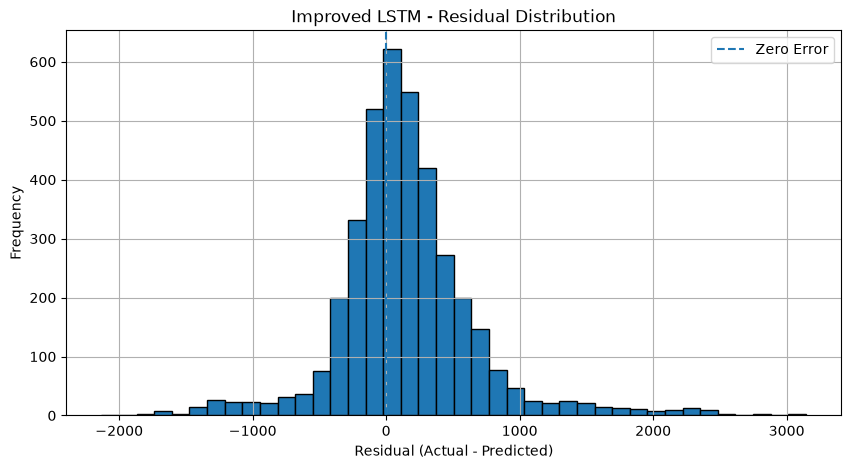

In [140]:
plt.figure(figsize=(10, 5))

plt.hist(
    residuals.flatten(),
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Improved LSTM - Residual Distribution")
plt.legend()
plt.grid(True)

plt.show()

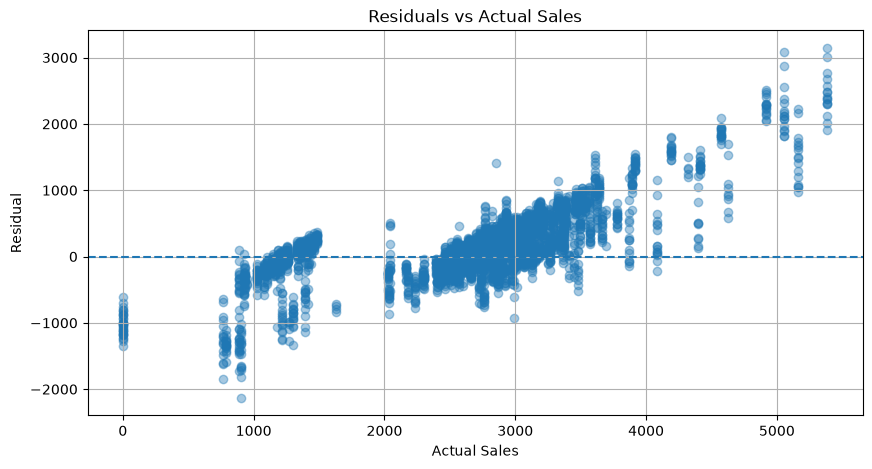

In [141]:
plt.figure(figsize=(10, 5))

plt.scatter(
    all_actuals_original_new.flatten(),
    residuals.flatten(),
    alpha=0.4
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Residual")
plt.title("Residuals vs Actual Sales")
plt.grid(True)

plt.show()

In [142]:
sales_level_df = pd.DataFrame({
    "actual_sales": all_actuals_original_new.flatten(),
    "predicted_sales": all_predictions_original_new.flatten()
})

sales_level_df["residual"] = (
    sales_level_df["actual_sales"]
    - sales_level_df["predicted_sales"]
)

sales_level_df["absolute_error"] = (
    sales_level_df["residual"].abs()
)

sales_level_df["sales_category"] = pd.cut(
    sales_level_df["actual_sales"],
    bins=[-1, 1000, 2000, 3000, 4000, float("inf")],
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

print(sales_level_df.head())

   actual_sales  predicted_sales     residual  absolute_error sales_category
0        2852.0      1439.379028  1412.620972     1412.620972         Medium
1        1177.0      1692.542114  -515.542114      515.542114            Low
2        3695.0      2997.436035   697.563965      697.563965           High
3        3099.0      2497.997314   601.002686      601.002686           High
4        4320.0      2822.375732  1497.624268     1497.624268      Very High


In [143]:
sales_level_metrics = (
    sales_level_df
    .groupby("sales_category", observed=False)
    .agg(
        MAE=("absolute_error", "mean"),
        Mean_Residual=("residual", "mean"),
        Average_Actual_Sales=("actual_sales", "mean"),
        Average_Predicted_Sales=("predicted_sales", "mean"),
        Total_Records=("actual_sales", "count")
    )
)

print(sales_level_metrics.round(2))

                        MAE  Mean_Residual  Average_Actual_Sales  \
sales_category                                                     
Very Low         923.919983    -922.070007            682.390015   
Low              222.740005    -123.129997           1267.250000   
Medium           209.070007      26.110001           2706.070068   
High             462.519989     441.579987           3286.290039   
Very High       1574.959961    1571.219971           4681.709961   

                Average_Predicted_Sales  Total_Records  
sales_category                                          
Very Low                    1604.459961            147  
Low                         1390.369995            508  
Medium                      2679.969971           1913  
High                        2844.709961           1104  
Very High                   3110.489990            152  


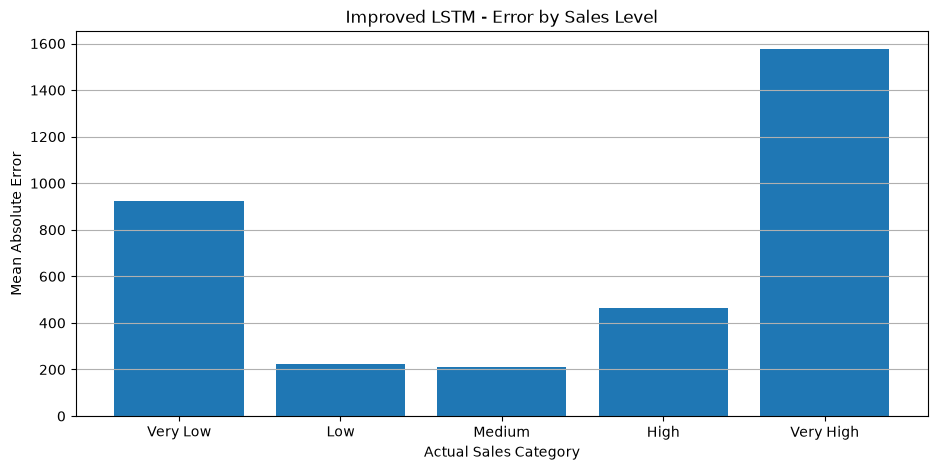

In [144]:
plt.figure(figsize=(11, 5))

plt.bar(
    sales_level_metrics.index.astype(str),
    sales_level_metrics["MAE"]
)

plt.xlabel("Actual Sales Category")
plt.ylabel("Mean Absolute Error")
plt.title("Improved LSTM - Error by Sales Level")
plt.grid(axis="y")

plt.show()

sales_category
Very Low      147
Low           508
Medium       1913
High         1104
Very High     152
Name: count, dtype: int64


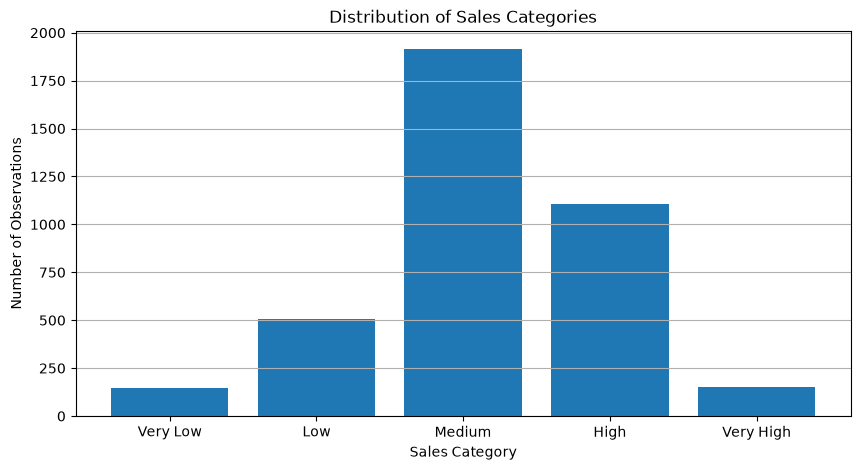

In [145]:
category_counts = (
    sales_level_df["sales_category"]
    .value_counts(sort=False)
)

print(category_counts)

plt.figure(figsize=(10, 5))

plt.bar(
    category_counts.index.astype(str),
    category_counts.values
)

plt.xlabel("Sales Category")
plt.ylabel("Number of Observations")
plt.title("Distribution of Sales Categories")
plt.grid(axis="y")

plt.show()

In [146]:
sales_level_df["absolute_percentage_error"] = (
    sales_level_df["absolute_error"]
    / sales_level_df["actual_sales"].replace(0, np.nan)
) * 100

category_mape = (
    sales_level_df
    .groupby("sales_category", observed=False)
    ["absolute_percentage_error"]
    .mean()
)

print(category_mape.round(2))

sales_category
Very Low     105.839996
Low           17.740000
Medium         7.790000
High          13.770000
Very High     32.959999
Name: absolute_percentage_error, dtype: float32


In [147]:
log_df = scaled_df.copy()

# Apply log1p to original sales
log_df["sales_log"] = np.log1p(log_df["sales"])

print(log_df[
    ["sales", "sales_log"]
].head(10))

    sales  sales_log
0     0.0   0.000000
1  2652.0   7.883446
2  2121.0   7.660114
3  2056.0   7.629004
4  2216.0   7.703910
5   723.0   6.584791
6  2262.0   7.724447
7  1782.0   7.486053
8  2429.0   7.795647
9  1544.0   7.342779


In [148]:
print("Original sales skewness:",
      log_df["sales"].skew())

print("Log sales skewness:",
      log_df["sales_log"].skew())

Original sales skewness: 0.5972330787962319
Log sales skewness: -7.4353703804847076


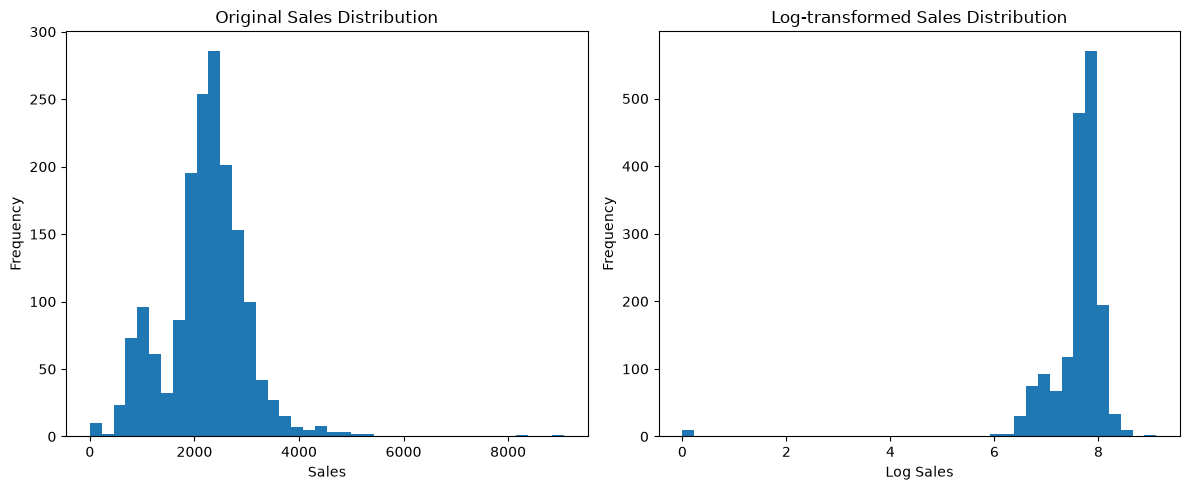

In [149]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(log_df["sales"], bins=40)
plt.title("Original Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(log_df["sales_log"], bins=40)
plt.title("Log-transformed Sales Distribution")
plt.xlabel("Log Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [150]:
from sklearn.preprocessing import MinMaxScaler

log_sales_scaler = MinMaxScaler()

log_sales_scaler.fit(
    log_df.iloc[:train_end][["sales_log"]]
)

log_df["sales_log_scaled"] = (
    log_sales_scaler.transform(
        log_df[["sales_log"]]
    )
)

print(
    "Training log target range:",
    log_df.iloc[:train_end]["sales_log_scaled"].min(),
    log_df.iloc[:train_end]["sales_log_scaled"].max()
)

Training log target range: 0.0 1.0


In [151]:
positive_sales = log_df.loc[
    log_df["sales"] > 0,
    "sales"
]

positive_log_sales = log_df.loc[
    log_df["sales"] > 0,
    "sales_log"
]

print(
    "Original positive sales skewness:",
    positive_sales.skew()
)

print(
    "Log positive sales skewness:",
    positive_log_sales.skew()
)

Original positive sales skewness: 0.7320449381884007
Log positive sales skewness: -1.11112233940638


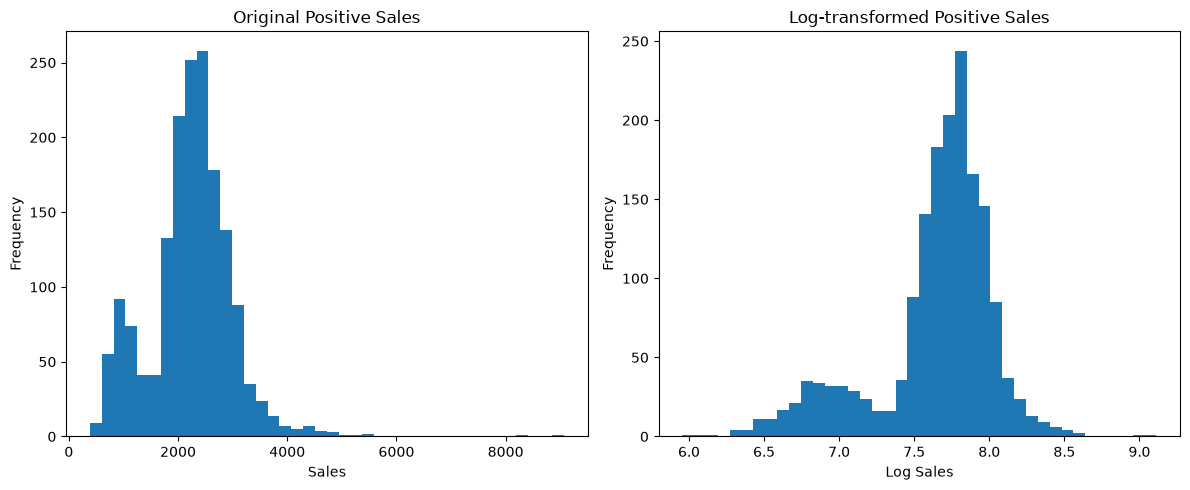

In [152]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.hist(positive_sales, bins=40)
plt.title("Original Positive Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)

plt.hist(positive_log_sales, bins=40)
plt.title("Log-transformed Positive Sales")
plt.xlabel("Log Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [153]:
LOG_HISTORICAL_FEATURES = [
    "sales_log_scaled",
    "promotion_scaled",
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend",
    "is_holiday"
]

LOG_FUTURE_FEATURES = [
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend",
    "is_holiday"
]

LOG_TARGET = "sales_log_scaled"

In [154]:
def create_log_sequences(
    data,
    start_idx,
    end_idx,
    lookback=LOOKBACK,
    horizon=HORIZON
):

    X_history = []
    X_future = []
    y = []

    for target_start in range(
        max(start_idx, lookback),
        end_idx - horizon + 1
    ):

        history = data.iloc[
            target_start - lookback:target_start
        ][LOG_HISTORICAL_FEATURES].values

        future = data.iloc[
            target_start:target_start + horizon
        ][LOG_FUTURE_FEATURES].values

        target = data.iloc[
            target_start:target_start + horizon
        ][LOG_TARGET].values

        X_history.append(history)
        X_future.append(future)
        y.append(target)

    return (
        np.array(X_history, dtype=np.float32),
        np.array(X_future, dtype=np.float32),
        np.array(y, dtype=np.float32)
    )

In [155]:
X_train_hist_log, X_train_future_log, y_train_log = (
    create_log_sequences(
        log_df,
        start_idx=0,
        end_idx=train_end
    )
)

X_val_hist_log, X_val_future_log, y_val_log = (
    create_log_sequences(
        log_df,
        start_idx=train_end,
        end_idx=val_end
    )
)

X_test_hist_log, X_test_future_log, y_test_log = (
    create_log_sequences(
        log_df,
        start_idx=val_end,
        end_idx=len(log_df)
    )
)

In [156]:
print("TRAINING")
print("Historical:", X_train_hist_log.shape)
print("Future:", X_train_future_log.shape)
print("Target:", y_train_log.shape)

print("\nVALIDATION")
print("Historical:", X_val_hist_log.shape)
print("Future:", X_val_future_log.shape)
print("Target:", y_val_log.shape)

print("\nTESTING")
print("Historical:", X_test_hist_log.shape)
print("Future:", X_test_future_log.shape)
print("Target:", y_test_log.shape)

TRAINING
Historical: (1076, 90, 6)
Future: (1076, 16, 4)
Target: (1076, 16)

VALIDATION
Historical: (238, 90, 6)
Future: (238, 16, 4)
Target: (238, 16)

TESTING
Historical: (239, 90, 6)
Future: (239, 16, 4)
Target: (239, 16)


In [157]:
import torch
from torch.utils.data import Dataset, DataLoader

In [158]:
class LogSalesDataset(Dataset):

    def __init__(self, X_history, X_future, y):

        self.X_history = torch.tensor(
            X_history,
            dtype=torch.float32
        )

        self.X_future = torch.tensor(
            X_future,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):

        return (
            self.X_history[index],
            self.X_future[index],
            self.y[index]
        )

In [159]:
class LogSalesDataset(Dataset):

    def __init__(self, X_history, X_future, y):

        self.X_history = torch.tensor(
            X_history,
            dtype=torch.float32
        )

        self.X_future = torch.tensor(
            X_future,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):

        return (
            self.X_history[index],
            self.X_future[index],
            self.y[index]
        )

In [160]:
BATCH_SIZE = 32

train_loader_log = DataLoader(
    train_dataset_log,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_log = DataLoader(
    val_dataset_log,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_log = DataLoader(
    test_dataset_log,
    batch_size=BATCH_SIZE,
    shuffle=False
)

NameError: name 'train_dataset_log' is not defined

In [161]:
train_dataset_log = LogSalesDataset(
    X_train_hist_log,
    X_train_future_log,
    y_train_log
)

val_dataset_log = LogSalesDataset(
    X_val_hist_log,
    X_val_future_log,
    y_val_log
)

test_dataset_log = LogSalesDataset(
    X_test_hist_log,
    X_test_future_log,
    y_test_log
)

print("Log datasets created successfully!")

Log datasets created successfully!


In [162]:
BATCH_SIZE = 32

train_loader_log = DataLoader(
    train_dataset_log,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_log = DataLoader(
    val_dataset_log,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_log = DataLoader(
    test_dataset_log,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Log DataLoaders created successfully!")

Log DataLoaders created successfully!


In [163]:
X_hist_batch, X_future_batch, y_batch = next(
    iter(train_loader_log)
)

print("Historical:", X_hist_batch.shape)
print("Future:", X_future_batch.shape)
print("Target:", y_batch.shape)

Historical: torch.Size([32, 90, 6])
Future: torch.Size([32, 16, 4])
Target: torch.Size([32, 16])


In [164]:
import torch
import torch.nn as nn
import torch.optim as optim

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create a fresh log-LSTM model
log_model = ImprovedSalesLSTM(
    historical_input_size=6,
    future_input_size=4
)

log_model = log_model.to(device)

# Loss function
criterion_log = nn.MSELoss()

# Optimizer
optimizer_log = optim.Adam(
    log_model.parameters(),
    lr=0.001
)

print("Log-LSTM initialized successfully!")
print("Device:", device)
print("Loss function:", criterion_log)
print("Optimizer:", optimizer_log)

NameError: name 'ImprovedSalesLSTM' is not defined

In [165]:
import torch
import torch.nn as nn


class ImprovedSalesLSTM(nn.Module):

    def __init__(
        self,
        historical_input_size=6,
        future_input_size=4,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        horizon=16
    ):

        super().__init__()

        # Process historical sales information
        self.lstm = nn.LSTM(
            input_size=historical_input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        # Process future calendar information
        self.future_fc = nn.Linear(
            future_input_size,
            hidden_size
        )

        # Combine historical and future information
        self.output = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x_history, x_future):

        # Extract historical information
        _, (hidden_state, cell_state) = self.lstm(x_history)

        context = hidden_state[-1]

        # Repeat historical context for 16 forecast days
        context = context.unsqueeze(1).expand(
            -1,
            x_future.size(1),
            -1
        )

        # Process future calendar features
        future_embedding = torch.relu(
            self.future_fc(x_future)
        )

        # Combine both representations
        combined = torch.cat(
            [context, future_embedding],
            dim=-1
        )

        # Generate 16 predictions
        predictions = self.output(combined).squeeze(-1)

        return predictions

In [166]:
import torch.optim as optim

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

log_model = ImprovedSalesLSTM(
    historical_input_size=6,
    future_input_size=4
).to(device)

criterion_log = nn.MSELoss()

optimizer_log = optim.Adam(
    log_model.parameters(),
    lr=0.001
)

print("Log-LSTM initialized successfully!")
print("Device:", device)
print("Loss function:", criterion_log)

Log-LSTM initialized successfully!
Device: cpu
Loss function: MSELoss()


In [167]:
log_model.eval()

with torch.no_grad():

    sample_predictions = log_model(
        X_hist_batch.to(device),
        X_future_batch.to(device)
    )

print("Predictions:", sample_predictions.shape)

Predictions: torch.Size([32, 16])


In [168]:
def train_log_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for X_history, X_future, y in train_loader:

        X_history = X_history.to(device)
        X_future = X_future.to(device)
        y = y.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Generate predictions
        predictions = model(X_history, X_future)

        # Calculate loss
        loss = criterion(predictions, y)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        batch_size = X_history.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

In [169]:
def validate_log_one_epoch(
    model,
    val_loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for X_history, X_future, y in val_loader:

            X_history = X_history.to(device)
            X_future = X_future.to(device)
            y = y.to(device)

            predictions = model(X_history, X_future)

            loss = criterion(predictions, y)

            batch_size = X_history.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

    return total_loss / total_samples

In [170]:
train_loss = train_log_one_epoch(
    log_model,
    train_loader_log,
    criterion_log,
    optimizer_log,
    device
)

val_loss = validate_log_one_epoch(
    log_model,
    val_loader_log,
    criterion_log,
    device
)

print("Training Loss:", train_loss)
print("Validation Loss:", val_loss)

Training Loss: 0.22521701655921883
Validation Loss: 0.022071434795355595


In [171]:
import copy
from pathlib import Path

EPOCHS = 50
PATIENCE = 7

best_val_loss = float("inf")
patience_counter = 0

log_history = {
    "train_loss": [],
    "val_loss": []
}

LOG_MODEL_PATH = Path("models/log_lstm_best.pth")
LOG_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

In [172]:
for epoch in range(EPOCHS):

    train_loss = train_log_one_epoch(
        log_model,
        train_loader_log,
        criterion_log,
        optimizer_log,
        device
    )

    val_loss = validate_log_one_epoch(
        log_model,
        val_loader_log,
        criterion_log,
        device
    )

    log_history["train_loss"].append(train_loss)
    log_history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}",
        end=" "
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            log_model.state_dict(),
            LOG_MODEL_PATH
        )

        print("Best model saved!")

    else:

        patience_counter += 1

        print(
            f"No improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break

print("\nLog-LSTM training completed!")
print("Best validation loss:", best_val_loss)

Epoch [1/50] Train Loss: 0.022333 Val Loss: 0.004838 Best model saved!
Epoch [2/50] Train Loss: 0.017904 Val Loss: 0.002359 Best model saved!
Epoch [3/50] Train Loss: 0.016418 Val Loss: 0.001753 Best model saved!
Epoch [4/50] Train Loss: 0.014878 Val Loss: 0.001829 No improvement: 1/7
Epoch [5/50] Train Loss: 0.014038 Val Loss: 0.001788 No improvement: 2/7
Epoch [6/50] Train Loss: 0.013372 Val Loss: 0.001735 Best model saved!
Epoch [7/50] Train Loss: 0.013052 Val Loss: 0.001602 Best model saved!
Epoch [8/50] Train Loss: 0.012895 Val Loss: 0.001251 Best model saved!
Epoch [9/50] Train Loss: 0.012716 Val Loss: 0.001418 No improvement: 1/7
Epoch [10/50] Train Loss: 0.012620 Val Loss: 0.001478 No improvement: 2/7
Epoch [11/50] Train Loss: 0.012594 Val Loss: 0.001350 No improvement: 3/7
Epoch [12/50] Train Loss: 0.012556 Val Loss: 0.001080 Best model saved!
Epoch [13/50] Train Loss: 0.012326 Val Loss: 0.001199 No improvement: 1/7
Epoch [14/50] Train Loss: 0.012315 Val Loss: 0.001108 No impr

In [173]:
log_model.load_state_dict(
    torch.load(
        LOG_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

log_model.eval()

print("Best Log-LSTM model loaded successfully!")

Best Log-LSTM model loaded successfully!


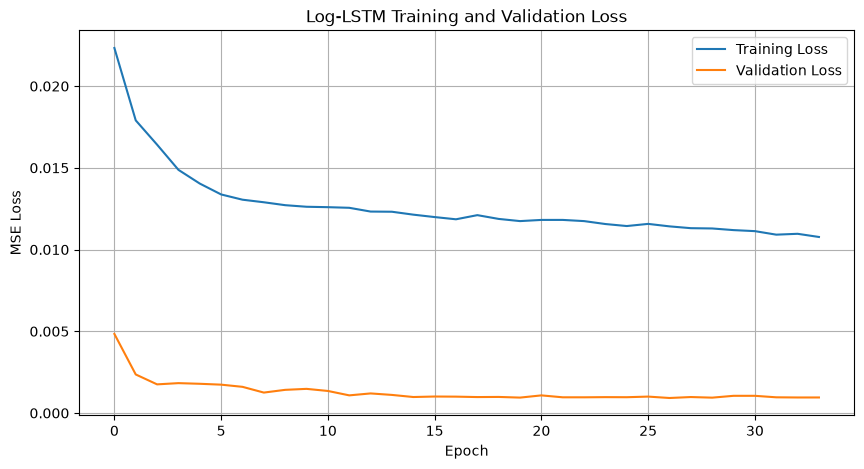

In [174]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    log_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    log_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Log-LSTM Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [175]:
import numpy as np
import torch

log_model.eval()

log_predictions_scaled = []
log_actuals_scaled = []

with torch.no_grad():

    for X_history, X_future, y in test_loader_log:

        X_history = X_history.to(device)
        X_future = X_future.to(device)

        predictions = log_model(X_history, X_future)

        log_predictions_scaled.append(
            predictions.cpu().numpy()
        )

        log_actuals_scaled.append(
            y.numpy()
        )

log_predictions_scaled = np.concatenate(
    log_predictions_scaled,
    axis=0
)

log_actuals_scaled = np.concatenate(
    log_actuals_scaled,
    axis=0
)

print("Predictions shape:", log_predictions_scaled.shape)
print("Actual values shape:", log_actuals_scaled.shape)

Predictions shape: (239, 16)
Actual values shape: (239, 16)


In [176]:
# Reverse MinMax scaling
predictions_log = log_sales_scaler.inverse_transform(
    log_predictions_scaled.reshape(-1, 1)
).flatten()

actuals_log = log_sales_scaler.inverse_transform(
    log_actuals_scaled.reshape(-1, 1)
).flatten()

# Reverse log transformation
log_predictions_original = np.expm1(predictions_log)
log_actuals_original = np.expm1(actuals_log)

# Sales cannot be negative
log_predictions_clipped = np.maximum(
    log_predictions_original, 0
)

print("Predictions:", log_predictions_clipped[:10])
print("Actual sales:", log_actuals_original[:10])

Predictions: [2037.5444 2218.777  4241.6826 3497.5698 3996.619  3624.745  1591.8628
 3818.4324 3460.0598 4241.6826]
Actual sales: [2851.9995 1177.0005 3695.0015 3099.0015 4319.9976 2972.     1417.0001
 2991.0002 4624.001  4393.9995]


In [177]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

mae_log = mean_absolute_error(
    log_actuals_original,
    log_predictions_clipped
)

rmse_log = np.sqrt(
    mean_squared_error(
        log_actuals_original,
        log_predictions_clipped
    )
)

non_zero_mask = log_actuals_original != 0

mape_log = np.mean(
    np.abs(
        (log_actuals_original[non_zero_mask]
         - log_predictions_clipped[non_zero_mask])
        / log_actuals_original[non_zero_mask]
    )
) * 100

print("Log-LSTM Test Results")
print("---------------------")
print("MAE:", round(mae_log, 2))
print("RMSE:", round(rmse_log, 2))
print("MAPE:", round(mape_log, 2), "%")

Log-LSTM Test Results
---------------------
MAE: 455.3
RMSE: 750.28
MAPE: 17.07 %


In [178]:
[
    (name, type(obj).__name__)
    for name, obj in globals().items()
    if isinstance(obj, ImprovedSalesLSTM)
]

[('log_model', 'ImprovedSalesLSTM')]

In [179]:
from pathlib import Path

models_dir = PROJECT_ROOT / "models"

print("Saved model files:")

for file in models_dir.iterdir():
    print(file.name)

Saved model files:


In [180]:
import torch.nn as nn

print("Available PyTorch models:")

for name, obj in globals().copy().items():
    if isinstance(obj, nn.Module):
        print(name, type(obj).__name__)

Available PyTorch models:
model SalesLSTM
criterion MSELoss
log_model ImprovedSalesLSTM
criterion_log MSELoss


In [181]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nProject root:")
print(PROJECT_ROOT)

print("\nAll model checkpoint files:")

for file in PROJECT_ROOT.rglob("*"):
    if file.is_file() and file.suffix in [".pth", ".pt", ".ckpt"]:
        print(file)

Notebook working directory:
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\notebooks

Project root:
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting

All model checkpoint files:
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\venv\Lib\site-packages\distutils-precedence.pth
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\notebooks\models\best_lstm_model.pth
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\notebooks\models\improved_best_lstm_model.pth
c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\notebooks\models\log_lstm_best.pth


In [182]:
variables_to_check = [
    "ImprovedSalesLSTM",
    "scaled_df",
    "train_loader",
    "val_loader",
    "test_loader",
    "train_loader_log",
    "val_loader_log",
    "test_loader_log",
    "sales_scaler",
    "promotion_scaler",
    "log_sales_scaler",
    "HISTORICAL_FEATURES",
    "FUTURE_FEATURES",
    "device"
]

for name in variables_to_check:
    print(f"{name}: {name in globals()}")

ImprovedSalesLSTM: True
scaled_df: True
train_loader: True
val_loader: True
test_loader: True
train_loader_log: True
val_loader_log: True
test_loader_log: True
sales_scaler: True
promotion_scaler: True
log_sales_scaler: True
HISTORICAL_FEATURES: True
FUTURE_FEATURES: True
device: True


In [183]:
print("Training history variables:")

for name in globals():
    if "history" in name.lower():
        print(name)

Training history variables:
history
history_sample
history_batch
fixed_history
fixed_history_tensor
log_history
X_history


In [184]:
print("History type:", type(history))
print("History content:", history)

History type: <class 'dict'>
History content: {'train_loss': [0.08941211680220405, 0.02662082172265505, 0.02192148974781586, 0.0194959279364425, 0.01851945517577757, 0.016751428522501957, 0.015714871735211643, 0.014717377978463599, 0.01447018635455782, 0.013970728922067521, 0.013609639974830319, 0.013274438983888874, 0.012924289971340767, 0.01271399114364031, 0.012832783166056008, 0.012142825757454541, 0.011753475324676604, 0.01196115549141368, 0.011757836936796466, 0.011149348746500493, 0.011194255639241531, 0.011290288485281973, 0.011072703651031376, 0.011057757059299149, 0.01082785903964344, 0.010650661999020435, 0.010615386647002626, 0.010247357030395681, 0.01028446513176186, 0.010004428776195723, 0.010150253294956729, 0.009989052637026655, 0.009777074420069894, 0.009529703615240227, 0.00986484398366018, 0.009695651857909438, 0.009618215169411389, 0.009669565955751669, 0.009204631789023105, 0.009459671789440967, 0.009387773423556059, 0.00930842051635666, 0.00902804151025071, 0.0089

In [185]:
print(ImprovedSalesLSTM)

<class '__main__.ImprovedSalesLSTM'>


In [186]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

X_batch, y_batch = next(iter(train_loader))

print("Historical input:", X_batch.shape)
print("Target:", y_batch.shape)

Training batches: 34
Validation batches: 8
Testing batches: 8
Historical input: torch.Size([32, 90, 2])
Target: torch.Size([32, 16])


In [187]:
print("Variables containing loader or dataset:\n")

for name, obj in globals().copy().items():

    if "loader" in name.lower() or "dataset" in name.lower():

        if hasattr(obj, "dataset"):
            print(
                name,
                "| Dataset:",
                type(obj.dataset).__name__,
                "| Samples:",
                len(obj.dataset)
            )

        elif hasattr(obj, "__len__"):
            print(
                name,
                "| Type:",
                type(obj).__name__,
                "| Samples:",
                len(obj)
            )

Variables containing loader or dataset:



TypeError: object of type 'type' has no len()

In [188]:
from torch.utils.data import DataLoader, Dataset

print("Available DataLoaders and Datasets:\n")

for name, obj in globals().copy().items():

    if isinstance(obj, DataLoader):

        print(
            f"{name}: DataLoader | "
            f"Samples: {len(obj.dataset)} | "
            f"Batches: {len(obj)}"
        )

    elif isinstance(obj, Dataset):

        print(
            f"{name}: Dataset | "
            f"Samples: {len(obj)}"
        )

Available DataLoaders and Datasets:

train_dataset: Dataset | Samples: 1076
val_dataset: Dataset | Samples: 238
test_dataset: Dataset | Samples: 239
train_loader: DataLoader | Samples: 1076 | Batches: 34
val_loader: DataLoader | Samples: 238 | Batches: 8
test_loader: DataLoader | Samples: 239 | Batches: 8
train_dataset_new: Dataset | Samples: 1076
val_dataset_new: Dataset | Samples: 238
test_dataset_new: Dataset | Samples: 239
train_loader_new: DataLoader | Samples: 1076 | Batches: 34
val_loader_new: DataLoader | Samples: 238 | Batches: 8
test_loader_new: DataLoader | Samples: 239 | Batches: 8
train_dataset_log: Dataset | Samples: 1076
val_dataset_log: Dataset | Samples: 238
test_dataset_log: Dataset | Samples: 239
train_loader_log: DataLoader | Samples: 1076 | Batches: 34
val_loader_log: DataLoader | Samples: 238 | Batches: 8
test_loader_log: DataLoader | Samples: 239 | Batches: 8


In [189]:
print("Historical features:", HISTORICAL_FEATURES)
print("Future features:", FUTURE_FEATURES)

Historical features: ['sales_scaled', 'promotion_scaled', 'day_of_week_sin', 'day_of_week_cos', 'is_weekend', 'is_holiday']
Future features: ['day_of_week_sin', 'day_of_week_cos', 'is_weekend', 'is_holiday']


In [190]:
# Inspect one sample from the new training dataset

X_history_new, X_future_new, y_new = train_dataset_new[0]

print("Historical input shape:", X_history_new.shape)
print("Future input shape:", X_future_new.shape)
print("Target shape:", y_new.shape)

print("\nFirst 5 historical target-feature values:")
print(X_history_new[:5, 0])

print("\nFirst 5 target values:")
print(y_new[:5])



Historical input shape: torch.Size([90, 6])
Future input shape: torch.Size([16, 4])
Target shape: torch.Size([16])

First 5 historical target-feature values:
tensor([0.0000, 0.5918, 0.4733, 0.4588, 0.4945])

First 5 target values:
tensor([0.5182, 0.4760, 0.5950, 0.3983, 0.4352])


In [191]:
print(type(train_dataset_new))
print(type(train_dataset_new).__init__.__code__.co_varnames)

<class '__main__.ImprovedSalesDataset'>
('self', 'X_history', 'X_future', 'y')


In [192]:
# Compare target values with both possible transformations

sample_target = y_new.numpy()

original_target = scaled_df["sales_scaled"].iloc[
    90:106
].to_numpy()

log_target = log_df["sales_log_scaled"].iloc[
    90:106
].to_numpy()

print("Dataset target:")
print(sample_target)

print("\nOriginal scaled sales:")
print(original_target)

print("\nLog-scaled sales:")
print(log_target)

print("\nDifference from original:")
print(np.max(np.abs(sample_target - original_target)))

print("\nDifference from log:")
print(np.max(np.abs(sample_target - log_target)))

Dataset target:
[0.5181879  0.47600982 0.59495646 0.39834857 0.4351707  0.43115377
 0.17763892 0.41397008 0.3738005  0.5503236  0.36710554 0.4385182
 0.41352376 0.16402589 0.41754073 0.44565946]

Original scaled sales:
[0.5181879  0.47600982 0.59495648 0.39834858 0.43517072 0.43115376
 0.17763892 0.4139701  0.37380049 0.55032359 0.36710556 0.43851819
 0.41352377 0.16402589 0.41754073 0.44565945]

Log-scaled sales:
[0.92183354 0.9117404  0.93825809 0.89056731 0.90107699 0.89997458
 0.79459967 0.89513985 0.88300667 0.9289868  0.88085845 0.90198792
 0.89501162 0.78512938 0.89616077 0.90390824]

Difference from original:
2.531301923625051e-08

Difference from log:
0.6211034874790512


In [193]:
improved_model = ImprovedSalesLSTM(
    historical_input_size=6,
    future_input_size=4,
    hidden_size=64,
    num_layers=2,
    dropout=0.2,
    horizon=16
).to(device)

print(improved_model)

ImprovedSalesLSTM(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (future_fc): Linear(in_features=4, out_features=64, bias=True)
  (output): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [194]:
from torch.utils.data import DataLoader

train_loader_new = DataLoader(
    train_dataset_new,
    batch_size=32,
    shuffle=True
)

val_loader_new = DataLoader(
    val_dataset_new,
    batch_size=32,
    shuffle=False
)

test_loader_new = DataLoader(
    test_dataset_new,
    batch_size=32,
    shuffle=False
)

In [195]:
from torch.utils.data import DataLoader

train_loader_new = DataLoader(
    train_dataset_new,
    batch_size=32,
    shuffle=True
)

val_loader_new = DataLoader(
    val_dataset_new,
    batch_size=32,
    shuffle=False
)

test_loader_new = DataLoader(
    test_dataset_new,
    batch_size=32,
    shuffle=False
)

In [196]:
X_history, X_future, y = next(iter(train_loader_new))

X_history = X_history.to(device)
X_future = X_future.to(device)

with torch.no_grad():
    predictions = improved_model(X_history, X_future)

print("Historical input:", X_history.shape)
print("Future input:", X_future.shape)
print("Target:", y.shape)
print("Predictions:", predictions.shape)

Historical input: torch.Size([32, 90, 6])
Future input: torch.Size([32, 16, 4])
Target: torch.Size([32, 16])
Predictions: torch.Size([32, 16])


In [197]:
import torch.optim as optim

criterion_improved = nn.MSELoss()

optimizer_improved = optim.Adam(
    improved_model.parameters(),
    lr=0.001
)

EPOCHS = 50
PATIENCE = 7

best_val_loss = float("inf")
patience_counter = 0

improved_history = {
    "train_loss": [],
    "val_loss": []
}

IMPROVED_MODEL_PATH = (
    PROJECT_ROOT / "models" / "improved_lstm_best.pth"
)

IMPROVED_MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

In [198]:
def train_improved_one_epoch(
    model, loader, criterion, optimizer, device
):
    model.train()

    total_loss = 0
    total_samples = 0

    for X_history, X_future, y in loader:

        X_history = X_history.to(device)
        X_future = X_future.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        predictions = model(X_history, X_future)

        loss = criterion(predictions, y)

        loss.backward()
        optimizer.step()

        batch_size = X_history.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


def validate_improved_one_epoch(
    model, loader, criterion, device
):
    model.eval()

    total_loss = 0
    total_samples = 0

    with torch.no_grad():

        for X_history, X_future, y in loader:

            X_history = X_history.to(device)
            X_future = X_future.to(device)
            y = y.to(device)

            predictions = model(X_history, X_future)

            loss = criterion(predictions, y)

            batch_size = X_history.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

    return total_loss / total_samples

In [199]:
for epoch in range(EPOCHS):

    train_loss = train_improved_one_epoch(
        improved_model,
        train_loader_new,
        criterion_improved,
        optimizer_improved,
        device
    )

    val_loss = validate_improved_one_epoch(
        improved_model,
        val_loader_new,
        criterion_improved,
        device
    )

    improved_history["train_loss"].append(train_loss)
    improved_history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}",
        end=" "
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            improved_model.state_dict(),
            IMPROVED_MODEL_PATH
        )

        print("Best model saved!")

    else:

        patience_counter += 1

        print(
            f"No improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break

print("\nImproved LSTM training completed!")
print("Best validation loss:", best_val_loss)

Epoch [1/50] Train Loss: 0.041252 Val Loss: 0.039105 Best model saved!
Epoch [2/50] Train Loss: 0.015616 Val Loss: 0.032953 Best model saved!
Epoch [3/50] Train Loss: 0.013112 Val Loss: 0.031710 Best model saved!
Epoch [4/50] Train Loss: 0.011842 Val Loss: 0.025279 Best model saved!
Epoch [5/50] Train Loss: 0.010423 Val Loss: 0.024502 Best model saved!
Epoch [6/50] Train Loss: 0.010263 Val Loss: 0.024119 Best model saved!
Epoch [7/50] Train Loss: 0.009866 Val Loss: 0.024554 No improvement: 1/7
Epoch [8/50] Train Loss: 0.009788 Val Loss: 0.024868 No improvement: 2/7
Epoch [9/50] Train Loss: 0.009707 Val Loss: 0.023856 Best model saved!
Epoch [10/50] Train Loss: 0.009554 Val Loss: 0.023964 No improvement: 1/7
Epoch [11/50] Train Loss: 0.009515 Val Loss: 0.024183 No improvement: 2/7
Epoch [12/50] Train Loss: 0.009532 Val Loss: 0.025754 No improvement: 3/7
Epoch [13/50] Train Loss: 0.009315 Val Loss: 0.024888 No improvement: 4/7
Epoch [14/50] Train Loss: 0.009304 Val Loss: 0.024433 No impr

In [200]:
improved_model.load_state_dict(
    torch.load(
        IMPROVED_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

improved_model.eval()

print("Best Improved LSTM checkpoint loaded!")
print("Saved at:", IMPROVED_MODEL_PATH)

Best Improved LSTM checkpoint loaded!
Saved at: c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\models\improved_lstm_best.pth


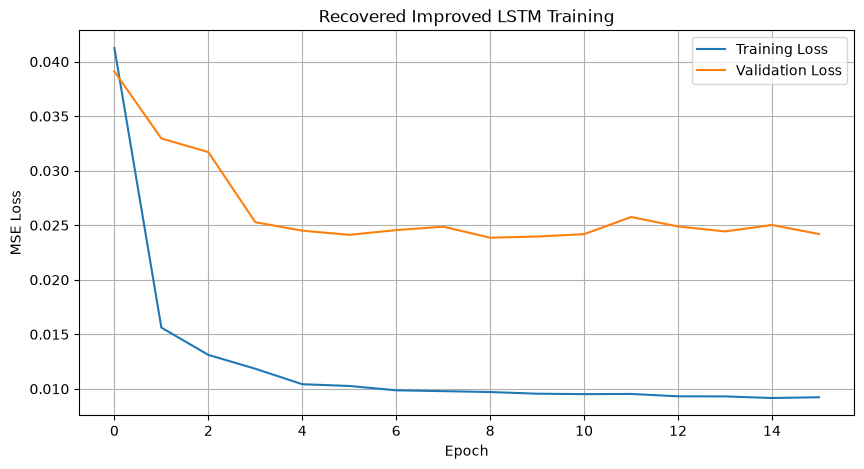

In [201]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    improved_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    improved_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Recovered Improved LSTM Training")

plt.legend()
plt.grid(True)
plt.show()

In [202]:
improved_model.eval()

predictions_scaled = []
actuals_scaled = []

with torch.no_grad():

    for X_history, X_future, y in test_loader_new:

        X_history = X_history.to(device)
        X_future = X_future.to(device)

        predictions = improved_model(
            X_history,
            X_future
        )

        predictions_scaled.append(
            predictions.cpu().numpy()
        )

        actuals_scaled.append(
            y.numpy()
        )

predictions_scaled = np.concatenate(
    predictions_scaled,
    axis=0
)

actuals_scaled = np.concatenate(
    actuals_scaled,
    axis=0
)

print("Predictions:", predictions_scaled.shape)
print("Actuals:", actuals_scaled.shape)

Predictions: (239, 16)
Actuals: (239, 16)


In [203]:
predictions_original = sales_scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).flatten()

actuals_original = sales_scaler.inverse_transform(
    actuals_scaled.reshape(-1, 1)
).flatten()

# Prevent negative sales predictions
predictions_original = np.maximum(
    predictions_original, 0
)

print("Predictions:", predictions_original[:10])
print("Actual sales:", actuals_original[:10])

Predictions: [2260.962  2428.2964 3278.4822 2747.1975 3019.0603 2666.5203 1389.5463
 2878.4917 2939.0332 3278.4822]
Actual sales: [2852.     1177.     3695.     3099.     4320.     2971.9998 1417.
 2991.     4624.     4394.    ]


In [204]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

mae_recovered = mean_absolute_error(
    actuals_original,
    predictions_original
)

rmse_recovered = np.sqrt(
    mean_squared_error(
        actuals_original,
        predictions_original
    )
)

non_zero_mask = actuals_original != 0

mape_recovered = np.mean(
    np.abs(
        (actuals_original[non_zero_mask]
         - predictions_original[non_zero_mask])
        / actuals_original[non_zero_mask]
    )
) * 100

print("Recovered Improved LSTM Results")
print("--------------------------------")
print("MAE:", round(mae_recovered, 2))
print("RMSE:", round(rmse_recovered, 2))
print("MAPE:", round(mape_recovered, 2), "%")

Recovered Improved LSTM Results
--------------------------------
MAE: 353.85
RMSE: 603.59
MAPE: 13.74 %


In [205]:
horizon_mae = np.mean(
    np.abs(
        actuals_original.reshape(239, 16)
        - predictions_original.reshape(239, 16)
    ),
    axis=0
)

for day, error in enumerate(horizon_mae, start=1):

    print(
        f"Forecast Day {day}: MAE = {error:.2f}"
    )

Forecast Day 1: MAE = 369.29
Forecast Day 2: MAE = 367.07
Forecast Day 3: MAE = 362.45
Forecast Day 4: MAE = 362.85
Forecast Day 5: MAE = 361.66
Forecast Day 6: MAE = 357.38
Forecast Day 7: MAE = 356.68
Forecast Day 8: MAE = 356.89
Forecast Day 9: MAE = 356.75
Forecast Day 10: MAE = 351.70
Forecast Day 11: MAE = 346.95
Forecast Day 12: MAE = 343.84
Forecast Day 13: MAE = 345.16
Forecast Day 14: MAE = 342.80
Forecast Day 15: MAE = 341.71
Forecast Day 16: MAE = 338.40


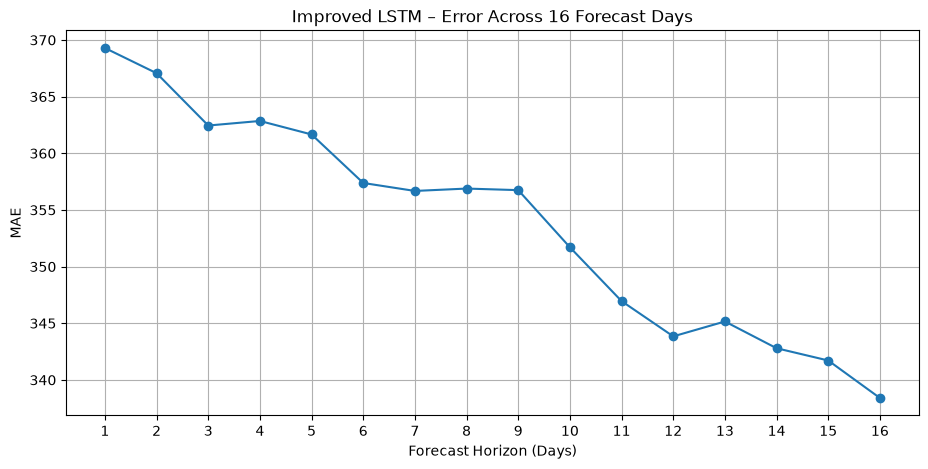

In [206]:
plt.figure(figsize=(11, 5))

plt.plot(
    range(1, 17),
    horizon_mae,
    marker="o"
)

plt.xlabel("Forecast Horizon (Days)")
plt.ylabel("MAE")
plt.title("Improved LSTM – Error Across 16 Forecast Days")

plt.xticks(range(1, 17))
plt.grid(True)

plt.show()

In [207]:
best_day = np.argmin(horizon_mae) + 1
worst_day = np.argmax(horizon_mae) + 1

print("Best forecast day:", best_day)
print("Lowest MAE:", round(horizon_mae[best_day - 1], 2))

print("\nWorst forecast day:", worst_day)
print("Highest MAE:", round(horizon_mae[worst_day - 1], 2))

Best forecast day: 16
Lowest MAE: 338.4

Worst forecast day: 1
Highest MAE: 369.29


In [208]:
# Reshape predictions and actual values
actual_matrix = actuals_original.reshape(239, 16)
prediction_matrix = predictions_original.reshape(239, 16)

# Calculate residuals
residuals = actual_matrix - prediction_matrix

# Flatten for overall analysis
actual_flat = actual_matrix.flatten()
prediction_flat = prediction_matrix.flatten()
residuals_flat = residuals.flatten()

print("Residual shape:", residuals_flat.shape)

print("Mean residual:", np.mean(residuals_flat))
print("Residual standard deviation:", np.std(residuals_flat))
print("Minimum residual:", np.min(residuals_flat))
print("Maximum residual:", np.max(residuals_flat))

Residual shape: (3824,)
Mean residual: 113.54781
Residual standard deviation: 592.8119
Minimum residual: -1614.8822
Maximum residual: 3802.7393


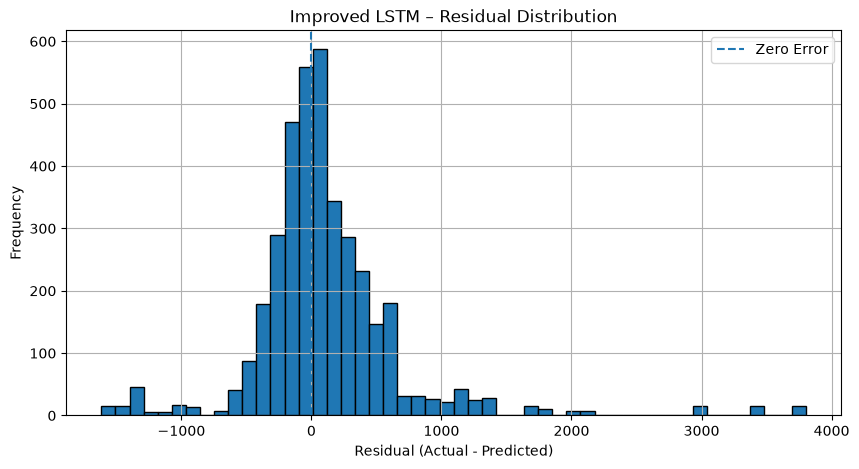

In [209]:
plt.figure(figsize=(10, 5))

plt.hist(
    residuals_flat,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Improved LSTM – Residual Distribution")

plt.legend()
plt.grid(True)

plt.show()

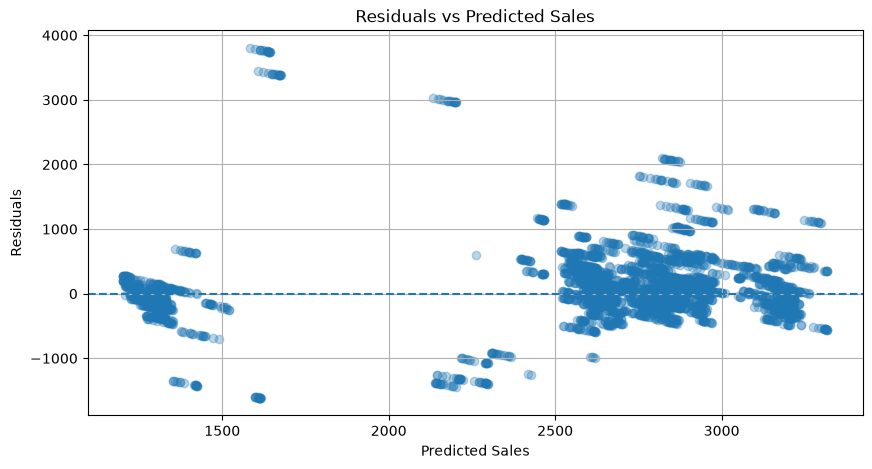

In [210]:
plt.figure(figsize=(10, 5))

plt.scatter(
    prediction_flat,
    residuals_flat,
    alpha=0.3
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Sales")

plt.grid(True)
plt.show()

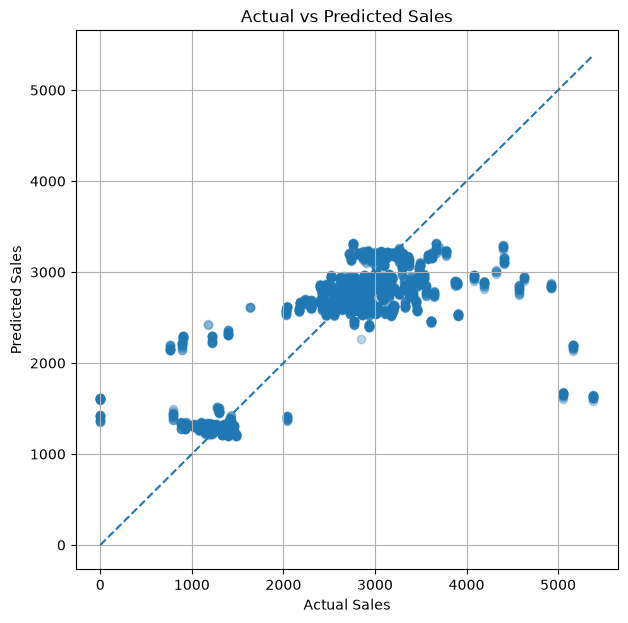

In [211]:
plt.figure(figsize=(7, 7))

plt.scatter(
    actual_flat,
    prediction_flat,
    alpha=0.3
)

min_value = min(actual_flat.min(), prediction_flat.min())
max_value = max(actual_flat.max(), prediction_flat.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.grid(True)
plt.show()

In [212]:
import pandas as pd
import numpy as np

sales_analysis_df = pd.DataFrame({
    "actual": actual_flat,
    "predicted": prediction_flat,
    "residual": residuals_flat
})

sales_analysis_df["absolute_error"] = np.abs(
    sales_analysis_df["residual"]
)

sales_analysis_df["sales_category"] = pd.cut(
    sales_analysis_df["actual"],
    bins=[-np.inf, 1000, 2000, 3000, 4000, np.inf],
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ],
    right=False
)

print(sales_analysis_df.head())

   actual    predicted     residual  absolute_error sales_category
0  2852.0  2260.961914   591.038086      591.038086         Medium
1  1177.0  2428.296387 -1251.296387     1251.296387            Low
2  3695.0  3278.482178   416.517822      416.517822           High
3  3099.0  2747.197510   351.802490      351.802490           High
4  4320.0  3019.060303  1300.939697     1300.939697      Very High


In [213]:
category_analysis = (
    sales_analysis_df
    .groupby("sales_category", observed=False)
    .agg(
        MAE=("absolute_error", "mean"),
        Mean_Residual=("residual", "mean"),
        Average_Actual=("actual", "mean"),
        Average_Predicted=("predicted", "mean"),
        Count=("actual", "count")
    )
)

category_analysis = category_analysis.round(2)

print(category_analysis)

                        MAE  Mean_Residual  Average_Actual  Average_Predicted  \
sales_category                                                                  
Very Low         978.039978    -978.039978      682.390015        1660.430054   
Low              188.759995    -108.949997     1267.250000        1376.189941   
Medium           186.350006     -52.000000     2706.070068        2758.070068   
High             399.279999     377.390015     3286.290039        2908.889893   
Very High       2080.020020    2080.020020     4681.709961        2601.689941   

                Count  
sales_category         
Very Low          147  
Low               508  
Medium           1913  
High             1104  
Very High         152  


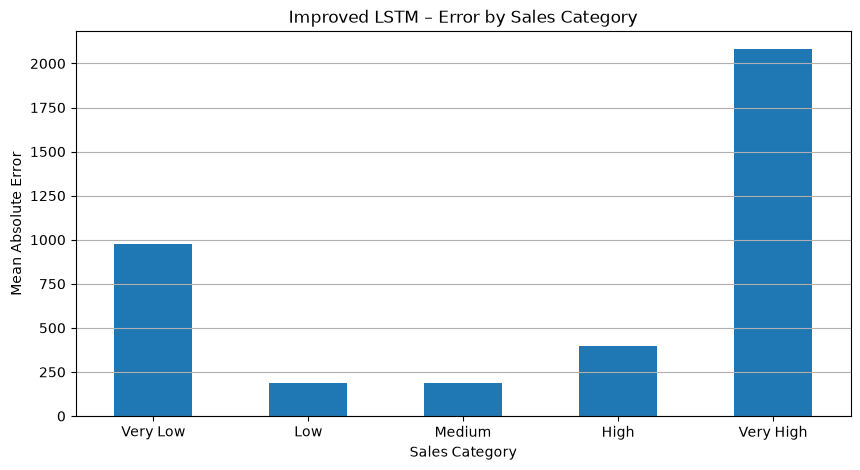

In [214]:
plt.figure(figsize=(10, 5))

category_analysis["MAE"].plot(
    kind="bar"
)

plt.xlabel("Sales Category")
plt.ylabel("Mean Absolute Error")
plt.title("Improved LSTM – Error by Sales Category")

plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [215]:
category_mape = (
    sales_analysis_df[
        sales_analysis_df["actual"] != 0
    ]
    .groupby("sales_category", observed=False)
    .apply(
        lambda group: np.mean(
            group["absolute_error"] / group["actual"]
        ) * 100,
        include_groups=False
    )
)

print("MAPE by Sales Category:")
print(category_mape.round(2))

MAPE by Sales Category:
sales_category
Very Low     97.540001
Low          15.050000
Medium        7.130000
High         11.790000
Very High    43.110001
dtype: float32


In [216]:
worst_predictions = (
    sales_analysis_df
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

print(
    worst_predictions[
        [
            "actual",
            "predicted",
            "residual",
            "absolute_error",
            "sales_category"
        ]
    ].to_string(index=False)
)

 actual   predicted    residual  absolute_error sales_category
 5386.0 1583.260620 3802.739258     3802.739258      Very High
 5386.0 1599.685425 3786.314453     3786.314453      Very High
 5386.0 1613.027832 3772.972168     3772.972168      Very High
 5386.0 1614.039307 3771.960693     3771.960693      Very High
 5386.0 1614.498413 3771.501465     3771.501465      Very High
 5386.0 1620.873901 3765.125977     3765.125977      Very High
 5386.0 1624.449585 3761.550293     3761.550293      Very High
 5386.0 1633.544800 3752.455078     3752.455078      Very High
 5386.0 1633.746460 3752.253418     3752.253418      Very High
 5386.0 1636.691650 3749.308350     3749.308350      Very High
 5386.0 1638.657471 3747.342529     3747.342529      Very High
 5386.0 1639.799072 3746.200928     3746.200928      Very High
 5386.0 1640.029419 3745.970703     3745.970703      Very High
 5386.0 1640.914551 3745.085449     3745.085449      Very High
 5386.0 1643.530518 3742.469482     3742.469482      Ve

In [217]:
print("Underprediction count:",
      (residuals_flat > 0).sum())

print("Overprediction count:",
      (residuals_flat < 0).sum())

print("Exact prediction count:",
      (residuals_flat == 0).sum())

Underprediction count: 2121
Overprediction count: 1703
Exact prediction count: 0


In [218]:
zero_sales_errors = sales_analysis_df[
    sales_analysis_df["actual"] == 0
]

print("Zero-sales observations:", len(zero_sales_errors))

if len(zero_sales_errors) > 0:
    print(
        "Average prediction for zero sales:",
        zero_sales_errors["predicted"].mean()
    )

    print(
        "Average absolute error:",
        zero_sales_errors["absolute_error"].mean()
    )

Zero-sales observations: 32
Average prediction for zero sales: 1502.2991
Average absolute error: 1502.2991


In [219]:
# Test set starts on 5 December 2016
test_start_date = pd.Timestamp("2016-12-05")

# Map each of the 239 forecast windows to its 16 target dates
date_offsets = (
    np.repeat(np.arange(239), 16)
    + np.tile(np.arange(16), 239)
)

prediction_dates = (
    test_start_date
    + pd.to_timedelta(date_offsets, unit="D")
)

# Create a date-aware evaluation DataFrame
dated_errors = pd.DataFrame({
    "date": prediction_dates,
    "actual": actual_flat,
    "predicted": prediction_flat,
    "residual": residuals_flat,
    "absolute_error": np.abs(residuals_flat)
})

print("Total prediction records:", len(dated_errors))
print("Unique dates:", dated_errors["date"].nunique())

Total prediction records: 3824
Unique dates: 254


In [220]:
date_error_summary = (
    dated_errors
    .groupby("date")
    .agg(
        actual_sales=("actual", "first"),
        average_prediction=("predicted", "mean"),
        average_absolute_error=("absolute_error", "mean"),
        prediction_count=("predicted", "count")
    )
    .sort_values("average_absolute_error", ascending=False)
)

print(date_error_summary.head(15).round(2))

            actual_sales  average_prediction  average_absolute_error  \
date                                                                   
2016-12-23        5386.0         1626.349976             3759.649902   
2016-12-22        5055.0         1657.089966             3397.909912   
2016-12-21        5162.0         2180.639893             2981.360107   
2017-03-07        4917.0         2846.239990             2070.760010   
2017-06-20        4575.0         2815.310059             1759.689941   
2016-12-13        4624.0         2936.510010             1687.489990   
2016-12-25           0.0         1608.199951             1608.199951   
2017-02-27         762.0         2161.790039             1399.790039   
2017-01-01           0.0         1396.400024             1396.400024   
2017-04-01        3912.0         2529.209961             1382.790039   
2016-12-26         904.0         2285.189941             1381.189941   
2017-05-02        4193.0         2873.639893             1319.35

In [221]:
worst_dates = date_error_summary.head(15).reset_index()

date_features = model_df[
    ["date", "sales", "onpromotion"]
].copy()

date_features["date"] = pd.to_datetime(date_features["date"])

worst_dates = worst_dates.merge(
    date_features,
    on="date",
    how="left"
)

print(
    worst_dates[
        [
            "date",
            "actual_sales",
            "average_prediction",
            "average_absolute_error",
            "onpromotion"
        ]
    ].round(2).to_string(index=False)
)

      date  actual_sales  average_prediction  average_absolute_error  onpromotion
2016-12-23        5386.0         1626.349976             3759.649902        125.0
2016-12-22        5055.0         1657.089966             3397.909912        116.0
2016-12-21        5162.0         2180.639893             2981.360107        116.0
2017-03-07        4917.0         2846.239990             2070.760010         41.0
2017-06-20        4575.0         2815.310059             1759.689941         48.0
2016-12-13        4624.0         2936.510010             1687.489990        108.0
2016-12-25           0.0         1608.199951             1608.199951          0.0
2017-02-27         762.0         2161.790039             1399.790039         52.0
2017-01-01           0.0         1396.400024             1396.400024          0.0
2017-04-01        3912.0         2529.209961             1382.790039         39.0
2016-12-26         904.0         2285.189941             1381.189941         80.0
2017-05-02      

C:\Users\Anshika Singh\AppData\Local\Temp\ipykernel_21468\2476292295.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


In [222]:
investigation_dates = pd.to_datetime([
    "2016-12-21",
    "2016-12-22",
    "2016-12-23"
])

high_sales_dates = model_df[
    model_df["date"].isin(investigation_dates)
][["date", "sales", "onpromotion"]].copy()

print(high_sales_dates.to_string(index=False))

      date  sales  onpromotion
2016-12-21 5162.0        116.0
2016-12-22 5055.0        116.0
2016-12-23 5386.0        125.0


In [223]:
print("Holiday-related variables:\n")

for name, obj in globals().copy().items():

    if "holiday" in name.lower() or "event" in name.lower():

        if isinstance(obj, pd.DataFrame):
            print(name, "| DataFrame | Shape:", obj.shape)

        else:
            print(name, "|", type(obj).__name__)

Holiday-related variables:

holiday_dates | Series
holiday_check | DataFrame | Shape: (0, 3)
holidays_df | DataFrame | Shape: (350, 6)
holiday_types | list
store_holidays | DataFrame | Shape: (117, 6)


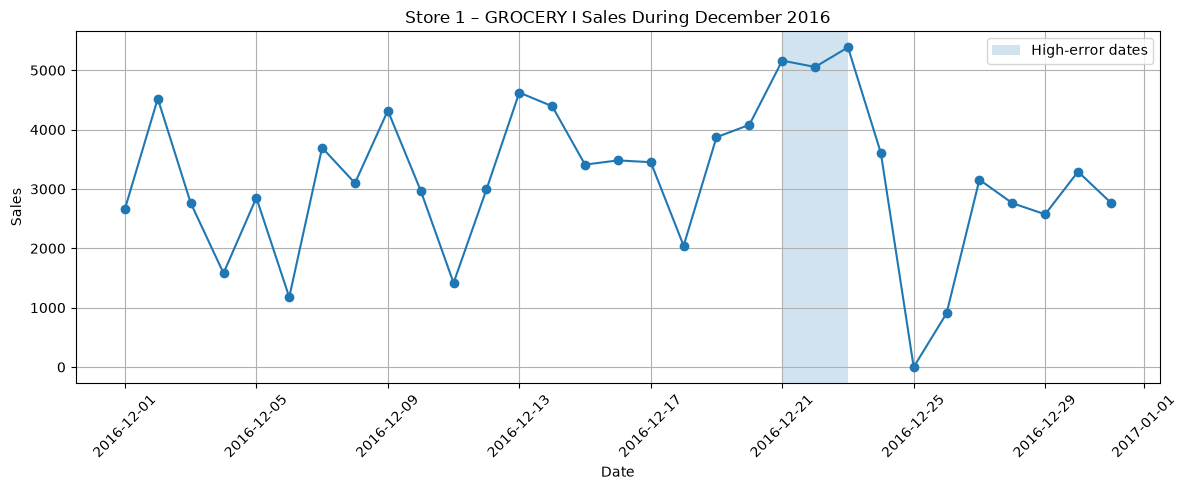

In [224]:
before_spike = model_df[
    (model_df["date"] >= "2016-12-01") &
    (model_df["date"] <= "2016-12-31")
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    before_spike["date"],
    before_spike["sales"],
    marker="o"
)

plt.axvspan(
    pd.Timestamp("2016-12-21"),
    pd.Timestamp("2016-12-23"),
    alpha=0.2,
    label="High-error dates"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Store 1 – GROCERY I Sales During December 2016")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [225]:
print("Holiday columns:")
print(holidays_df.columns.tolist())

print("\nHoliday records around December 2016:")

print(
    holidays_df[
        (pd.to_datetime(holidays_df["date"]) >= "2016-12-15") &
        (pd.to_datetime(holidays_df["date"]) <= "2016-12-31")
    ].to_string(index=False)
)

Holiday columns:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

Holiday records around December 2016:
      date       type   locale locale_name              description  transferred
2016-12-21 Additional National     Ecuador                Navidad-4        False
2016-12-22 Additional National     Ecuador                Navidad-3        False
2016-12-22    Holiday    Local     Salinas Cantonizacion de Salinas        False
2016-12-23 Additional National     Ecuador                Navidad-2        False
2016-12-24 Additional National     Ecuador                Navidad-1        False
2016-12-25    Holiday National     Ecuador                  Navidad        False
2016-12-26 Additional National     Ecuador                Navidad+1        False
2016-12-31 Additional National     Ecuador     Primer dia del ano-1        False


In [226]:
print(
    store_holidays[
        (pd.to_datetime(store_holidays["date"]) >= "2016-12-15") &
        (pd.to_datetime(store_holidays["date"]) <= "2016-12-31")
    ].to_string(index=False)
)

      date       type   locale locale_name          description  transferred
2016-12-21 Additional National     Ecuador            Navidad-4        False
2016-12-22 Additional National     Ecuador            Navidad-3        False
2016-12-23 Additional National     Ecuador            Navidad-2        False
2016-12-24 Additional National     Ecuador            Navidad-1        False
2016-12-25    Holiday National     Ecuador              Navidad        False
2016-12-26 Additional National     Ecuador            Navidad+1        False
2016-12-31 Additional National     Ecuador Primer dia del ano-1        False


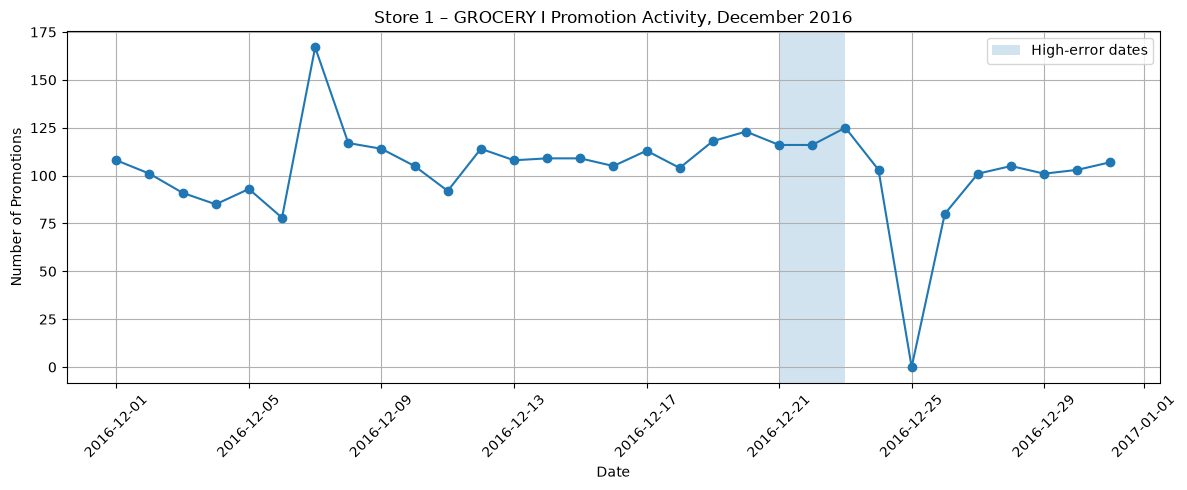

In [227]:
december_promotions = model_df[
    (model_df["date"] >= "2016-12-01") &
    (model_df["date"] <= "2016-12-31")
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    december_promotions["date"],
    december_promotions["onpromotion"],
    marker="o"
)

plt.axvspan(
    pd.Timestamp("2016-12-21"),
    pd.Timestamp("2016-12-23"),
    alpha=0.2,
    label="High-error dates"
)

plt.xlabel("Date")
plt.ylabel("Number of Promotions")
plt.title("Store 1 – GROCERY I Promotion Activity, December 2016")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [228]:
from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path.cwd().parent

MODEL_DIR = PROJECT_ROOT / "models"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

MODEL_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

# Verify the trained model checkpoint
checkpoint_path = MODEL_DIR / "improved_lstm_best.pth"

assert checkpoint_path.exists(), "Model checkpoint not found!"

# Save preprocessing scalers
joblib.dump(
    sales_scaler,
    ARTIFACT_DIR / "sales_scaler.pkl"
)

joblib.dump(
    promotion_scaler,
    ARTIFACT_DIR / "promotion_scaler.pkl"
)

# Save model configuration and feature information
metadata = {
    "model_name": "ImprovedSalesLSTM",
    "input_size": 6,
    "future_input_size": 4,
    "hidden_size": 64,
    "num_layers": 2,
    "dropout": 0.2,
    "lookback_window": 90,
    "forecast_horizon": 16,
    "historical_features": [
        "sales_scaled",
        "promotion_scaled",
        "day_of_week_sin",
        "day_of_week_cos",
        "is_weekend",
        "is_holiday"
    ],
    "future_features": [
        "day_of_week_sin",
        "day_of_week_cos",
        "is_weekend",
        "is_holiday"
    ],
    "target": "sales_scaled"
}

with open(ARTIFACT_DIR / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Phase 8 artifacts saved!")
print("Model:", checkpoint_path)
print("Sales scaler saved")
print("Promotion scaler saved")
print("Metadata saved")

Phase 8 artifacts saved!
Model: c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\models\improved_lstm_best.pth
Sales scaler saved
Promotion scaler saved
Metadata saved


In [229]:
for folder in [MODEL_DIR, ARTIFACT_DIR]:
    print(f"\n{folder.name}/")

    for file in folder.iterdir():
        print("  ", file.name)


models/
   improved_lstm_best.pth

artifacts/
   final_model_comparison.csv
   model_comparison.csv
   model_metadata.json
   promotion_scaler.pkl
   sales_scaler.pkl


In [230]:
checkpoint = torch.load(
    PROJECT_ROOT / "models" / "improved_lstm_best.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:15])

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'lstm.weight_ih_l1', 'lstm.weight_hh_l1', 'lstm.bias_ih_l1', 'lstm.bias_hh_l1', 'future_fc.weight', 'future_fc.bias', 'output.0.weight', 'output.0.bias', 'output.3.weight', 'output.3.bias']


In [231]:
self.model.load_state_dict(checkpoint)

NameError: name 'self' is not defined

In [232]:
from src.model import ImprovedSalesLSTM

ImportError: cannot import name 'ImprovedSalesLSTM' from 'src.model' (c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\src\model.py)

In [233]:
from src.predict import SalesPredictor

predictor = SalesPredictor()

print("Saved model loaded successfully!")

ImportError: cannot import name 'ImprovedSalesLSTM' from 'src.model' (c:\Users\Anshika Singh\Desktop\ai-sales-forecasting\src\model.py)

In [234]:
import importlib
import src.model

importlib.reload(src.model)

from src.model import ImprovedSalesLSTM

print("Model imported successfully!")

Model imported successfully!


In [235]:
model = ImprovedSalesLSTM()

print(model)

ImprovedSalesLSTM(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (future_fc): Linear(in_features=4, out_features=64, bias=True)
  (output): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [236]:
checkpoint = torch.load(
    PROJECT_ROOT / "models" / "improved_lstm_best.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint)

print("Checkpoint loaded successfully!")

Checkpoint loaded successfully!


In [237]:
import importlib
import src.predict

importlib.reload(src.predict)

from src.predict import SalesPredictor

In [238]:
predictor = SalesPredictor()

X_history_batch, X_future_batch, y_batch = next(
    iter(test_loader_new)
)

forecast = predictor.predict(
    X_history_batch[0].numpy(),
    X_future_batch[0].numpy()
)

print("Forecast shape:", forecast.shape)
print("\n16-Day Sales Forecast:")

for day, sales in enumerate(forecast, start=1):
    print(f"Day {day}: {sales:.2f}")

TypeError: ImprovedSalesLSTM.__init__() got an unexpected keyword argument 'hidden_size'

In [239]:
historical_input_size
future_input_size

NameError: name 'historical_input_size' is not defined

In [240]:
import importlib
import src.predict

importlib.reload(src.predict)

from src.predict import SalesPredictor

In [241]:
predictor = SalesPredictor()

print("Model loaded successfully!")

Model loaded successfully!


In [242]:
X_history_batch, X_future_batch, y_batch = next(
    iter(test_loader_new)
)

forecast = predictor.predict(
    X_history_batch[0].numpy(),
    X_future_batch[0].numpy()
)

print("Forecast shape:", forecast.shape)

for day, sales in enumerate(forecast, start=1):
    print(f"Day {day}: {sales:.2f}")

Forecast shape: (16,)
Day 1: 2260.96
Day 2: 2428.30
Day 3: 3278.48
Day 4: 2747.20
Day 5: 3019.06
Day 6: 2666.52
Day 7: 1389.55
Day 8: 2878.49
Day 9: 2939.03
Day 10: 3278.48
Day 11: 2747.20
Day 12: 3019.06
Day 13: 2666.52
Day 14: 1389.55
Day 15: 2878.49
Day 16: 2939.03


In [243]:
import json

# Get one sample from the test dataset
X_history_batch, X_future_batch, y_batch = next(
    iter(test_loader_new)
)

# Prepare API request
payload = {
    "historical_features": X_history_batch[0].numpy().tolist(),
    "future_features": X_future_batch[0].numpy().tolist()
}

# Print JSON for Swagger
print(json.dumps(payload))

{"historical_features": [[0.656773030757904, 0.24637681245803833, 0.7818315029144287, 0.6234897971153259, 0.0, 0.0], [0.5904932022094727, 0.37681159377098083, 0.9749279022216797, -0.22252093255519867, 0.0, 0.0], [0.5311314463615417, 0.30434781312942505, 0.4338837265968323, -0.9009688496589661, 0.0, 0.0], [0.5811203122138977, 0.36231884360313416, -0.4338837265968323, -0.9009688496589661, 0.0, 0.0], [0.5288997888565063, 0.2753623127937317, -0.9749279022216797, -0.22252093255519867, 1.0, 0.0], [0.23633117973804474, 0.15942029654979706, -0.7818315029144287, 0.6234897971153259, 1.0, 0.0], [0.5945101380348206, 0.260869562625885, 0.0, 1.0, 0.0, 0.0], [0.5853604078292847, 0.0, 0.7818315029144287, 0.6234897971153259, 0.0, 0.0], [0.5795581340789795, 0.3333333432674408, 0.9749279022216797, -0.22252093255519867, 0.0, 0.0], [0.5110466480255127, 0.4057970941066742, 0.4338837265968323, -0.9009688496589661, 0.0, 0.0], [0.5858067274093628, 0.4057970941066742, -0.4338837265968323, -0.9009688496589661, 0

In [244]:
import json

X_history_batch, X_future_batch, y_batch = next(
    iter(test_loader_new)
)

payload = {
    "historical_features": X_history_batch[0].numpy().tolist(),
    "future_features": X_future_batch[0].numpy().tolist()
}

print(json.dumps(payload, indent=2))

{
  "historical_features": [
    [
      0.656773030757904,
      0.24637681245803833,
      0.7818315029144287,
      0.6234897971153259,
      0.0,
      0.0
    ],
    [
      0.5904932022094727,
      0.37681159377098083,
      0.9749279022216797,
      -0.22252093255519867,
      0.0,
      0.0
    ],
    [
      0.5311314463615417,
      0.30434781312942505,
      0.4338837265968323,
      -0.9009688496589661,
      0.0,
      0.0
    ],
    [
      0.5811203122138977,
      0.36231884360313416,
      -0.4338837265968323,
      -0.9009688496589661,
      0.0,
      0.0
    ],
    [
      0.5288997888565063,
      0.2753623127937317,
      -0.9749279022216797,
      -0.22252093255519867,
      1.0,
      0.0
    ],
    [
      0.23633117973804474,
      0.15942029654979706,
      -0.7818315029144287,
      0.6234897971153259,
      1.0,
      0.0
    ],
    [
      0.5945101380348206,
      0.260869562625885,
      0.0,
      1.0,
      0.0,
      0.0
    ],
    [
      0.58536040

In [245]:
import json

with open("prediction_request.json", "w") as file:
    json.dump(payload, file, indent=2)

print("Complete JSON saved successfully!")

Complete JSON saved successfully!
